# Лабораторная работа №3. Классификация: логистическая регрессия

**Данные:** UCI Bike Sharing Dataset (hourly) — тот же датасет, что и в ЛР №2 (`data/bike_sharing_hourly.csv`).

**Целевая переменная `high_demand`:** 1 — «пиковый» час (за час взяли **≥ 280** велосипедов), 0 — обычный или спокойный час.

## Описание признаков

| Признак | Тип | Описание |
| :-- | :-- | :-- |
| `cnt` | числовой (регрессия) | фактическое число прокатов за час — **источник целевой переменной** |
| `high_demand` | **цель, бинарная** | 1 = пиковый час (`cnt` ≥ 280), 0 = иначе |
| `temp` | непрерывный | нормированная температура воздуха |
| `atemp` | непрерывный | нормированная «ощущаемая» температура |
| `hum` | непрерывный | нормированная относительная влажность |
| `windspeed` | непрерывный | нормированная скорость ветра |
| `hour_temp_gap` | непрерывный | `temp` минус медианная `temp` в этот же час суток |
| `hr` | категориальный | час суток 0–23 |
| `season` | категориальный | 1 = весна, 2 = лето, 3 = осень, 4 = зима |
| `weathersit` | категориальный | 1 = ясно, 2 = туман, 3 = дождь/снег, 4 = ливень |
| `weekday` | категориальный | день недели (0 = воскресенье … 6 = суббота) |
| `mnth` | категориальный | месяц 1–12 |
| `yr` | категориальный | 0 = 2011, 1 = 2012 |
| `holiday` | категориальный | 1 = праздник |
| `workingday` | категориальный | 1 = рабочий день |
| `casual`, `registered` | **запрещённые** | части того же `cnt` — прямая утечка целевой переменной |

## Две исследовательские гипотезы (п. «До выполнения экспериментов»)

> **H1. Стандартизация числовых признаков улучшит качество регуляризованной (`C = 1`) логистической регрессии по `F1-score` и `ROC-AUC` по сравнению с моделью без масштабирования.**
> *Логика:* штраф L2 действует на коэффициенты в их единицах. Без масштабирования `temp` (0–1) и `hour_temp_gap` (≈ −0.5…0.5) получают разный масштаб, и штраф наказывает признаки неравномерно — решение становится смещённым.

> **H2. `class_weight='balanced'` (или ресемплинг) увеличит `Recall` положительного класса по сравнению с базовой моделью.**
> *Логика:* при 25% положительного класса базовый классификатор «склоняется» к отрицательному классу; веса классов смещают границу в сторону редкого класса.

Дополнительно проверим H3: **подбор порога классификации повысит `F1-score` по сравнению с порогом 0.5**.

In [1]:
import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, roc_auc_score, average_precision_score,
    confusion_matrix, roc_curve, precision_recall_curve
)

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = SEED
TARGET = "high_demand"
THRESHOLD_CNT = 280   # порог "пикового" часа

print(f"pandas {pd.__version__}, numpy {np.__version__}, sklearn {__import__('sklearn').__version__}")

pandas 3.0.6, numpy 2.5.3, sklearn 1.9.1


In [2]:
# Загрузка данных. Локально — файл из data/; в Colab — кнопка загрузки.
DATA_PATH = "data/bike_sharing_hourly.csv"

if not os.path.exists(DATA_PATH):
    from google.colab import files
    import io
    uploaded = files.upload()
    raw = pd.read_csv(io.BytesIO(next(iter(uploaded.values()))))
else:
    raw = pd.read_csv(DATA_PATH)

# Расшифровка кодов UCI в читаемые строки (в модель они пойдут как категории)
df = raw.copy()
df["season"] = df["season"].map({1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"})
df["weathersit"] = df["weathersit"].map({1: "Clear", 2: "Mist", 3: "LightRainSnow", 4: "HeavyRainSnow"})
# ВНИМАНИЕ: в UCI weekday кодируется начиная с воскресенья (0 = Sun, 6 = Sat)
df["weekday"] = df["weekday"].map({0: "Sun", 1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat"})
df["yr"] = df["yr"].map({0: "2011", 1: "2012"})
df["holiday"] = df["holiday"].map({0: "No", 1: "Yes"})
df["workingday"] = df["workingday"].map({0: "No", 1: "Yes"})

# Бинарная целевая переменная
df[TARGET] = (df["cnt"] >= THRESHOLD_CNT).astype(int)

print(f"Строк: {df.shape[0]}, столбцов: {df.shape[1]}")
display(df.head())

Строк: 17379, столбцов: 18


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,period,hour_temp_gap,high_demand
0,Spring,2011,1,0,No,Sat,No,Clear,0.24,0.2879,0.81,0.0,3,13,16,1,0.22,0
1,Spring,2011,1,1,No,Sat,No,Clear,0.22,0.2727,0.80,0.0,8,32,40,1,0.24,0
2,Spring,2011,1,2,No,Sat,No,Clear,0.22,0.2727,0.80,0.0,5,27,32,1,0.24,0
3,Spring,2011,1,3,No,Sat,No,Clear,0.24,0.2879,0.75,0.0,3,10,13,1,0.22,0
4,Spring,2011,1,4,No,Sat,No,Clear,0.24,0.2879,0.75,0.0,0,1,1,1,0.20,0


### 1.1. Предметная область, единица наблюдения, целевая переменная, цена ошибок

**Предметная область.** Городская велопрокатная система (Capital Bikeshare, Вашингтон, 2011–2012). Оператору нужно заранее знать, в какие часы спрос окажется аномально высоким, чтобы:

- подвозить велосипеды к станциям и не допускать «пустых» стойек;
- планировать смены персонала, ремонтных бригад и перевозчиков;
- не держать лишние машины в спокойные часы.

**Единица наблюдения.** Один час работы системы: календарь, погода в этот час и итоговое число прокатов.

**Целевая переменная** `high_demand`:
- `1` — пиковый час (≥ 280 прокатов), «высокий спрос»;
- `0` — обычный или спокойный час.

**Цена ошибок:**

- **Ошибка первого рода (`FP`):** модель предсказала пик, а пика не было. Оператор зря подвёз велосипеды, вывел дополнительный персонал и технику — **прямые деньги**, но система остаётся работоспособной.
- **Ошибка второго рода (`FN`):** пик случился, а модель его не заметила. Станции опустели, клиенты не смогли взять велосипед, выросло число обращений и жалоб, часть поездок перешла к конкурентам (такси, метро) — **потерянная выручка и репутация**.

Для велопроката `FN` обычно **дороже**: пустые стойки в час пика — это публичная, видимая всем проблема, а «лишний» подвоз велосипедов — незначительные издержки, которые частично окупаются, если велосипеды просто простояли. Поэтому в п. 6 мы специально рассмотрим порог, который **поднимает Recall** даже ценой роста FP.

### 1.2. Какой класс положительный и почему?

**Положительный класс — `1` («пиковый час», `cnt` ≥ 280).**

Причины:

1. Именно пиковый час — то событие, ради которого строится модель: операционные дефициты велосипедов и персонала возникают только в пики.
2. Положительный класс редкий (≈ 25%) — это «событие», которое нужно *найти* среди 75% обычных часов. Выбор редкого класса положительным делает `Recall` и `Precision` осмысленными для оператора: «сколько реальных пиков мы поймали» и «сколько наших предсказаний пиков оказались верными».
3. При таком выборе `FN` = пропущенный пик, что соответствует более дорогой ошибке из п. 1.1.

Класс `0` (обычный / спокойный час) — отрицательный.

### 1.3. Распределения числовых признаков по классам

Распределение целевой переменной:


,Количество
high_demand,
0 — обычный час,12997
1 — пиковый час,4382



Сводка числовых признаков по классам:


temp                atemp                  hum               windspeed               hour_temp_gap                    cnt                
              mean median    std   mean median    std   mean median    std      mean median    std          mean median    std     mean median      std
high_demand                                                                                                                                            
0            0.459   0.44  0.187  0.442  0.439  0.169  0.654   0.66  0.190     0.186  0.164  0.124         0.033   0.04  0.189  102.430   87.0   83.017
1            0.611   0.64  0.161  0.576  0.621  0.139  0.545   0.53  0.176     0.202  0.194  0.117        -0.078  -0.10  0.155  447.602  407.0  144.715

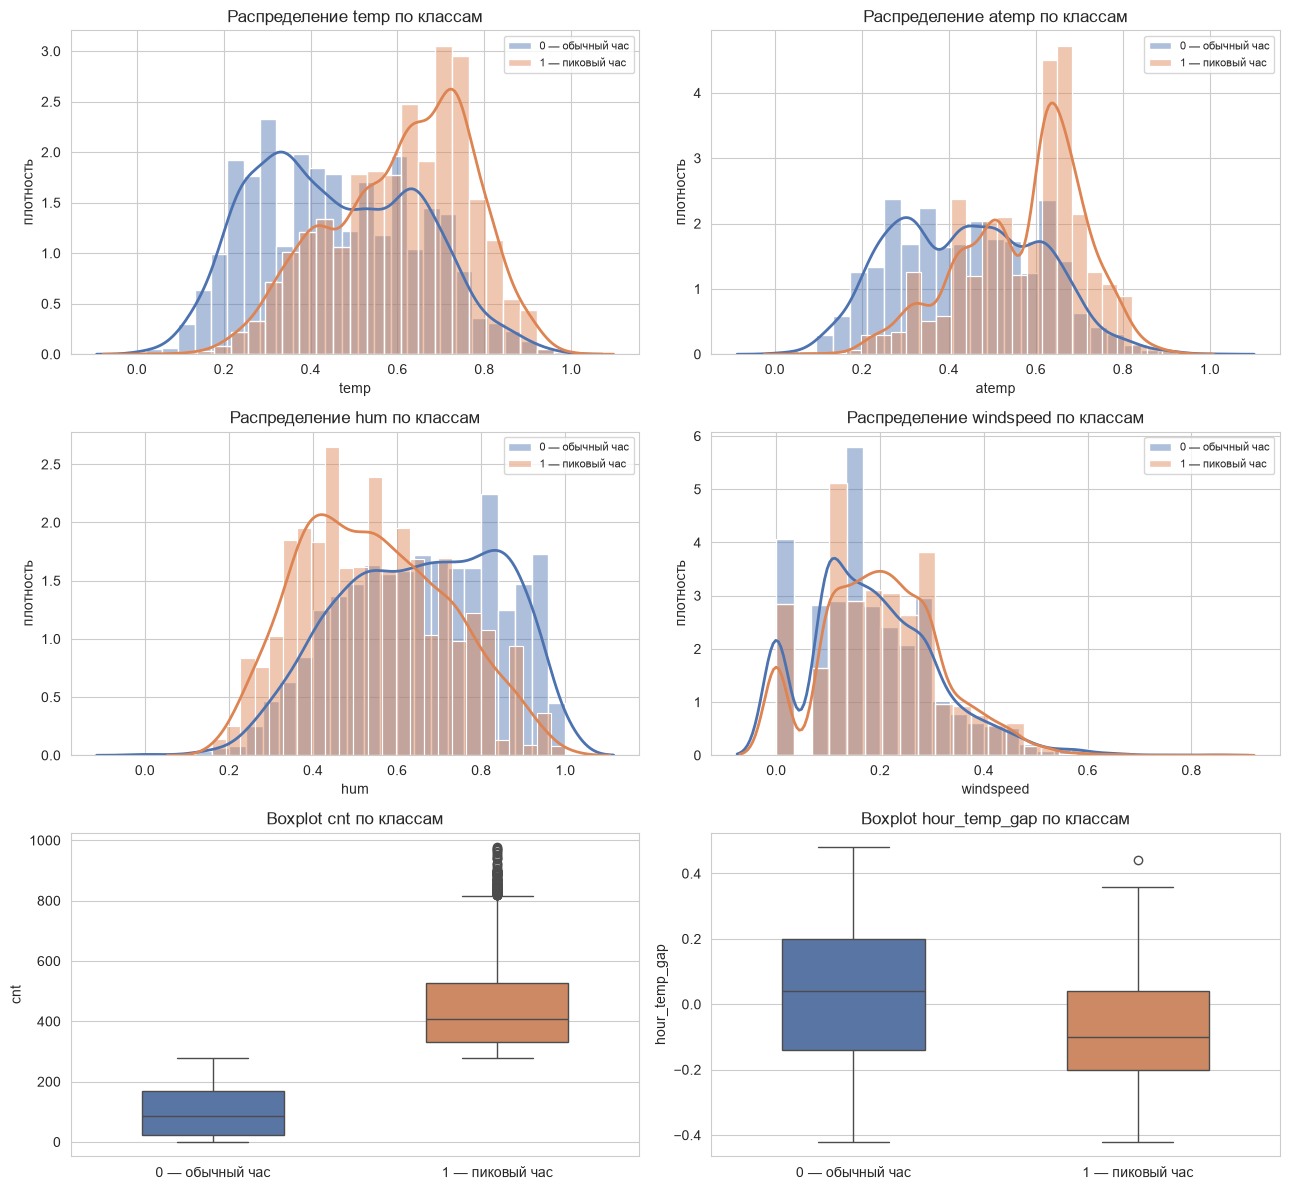

In [3]:
num_cols = ["temp", "atemp", "hum", "windspeed", "hour_temp_gap", "cnt"]
cat_cols = ["hr", "season", "weathersit", "weekday", "mnth", "yr", "holiday", "workingday"]

print("Распределение целевой переменной:")
display(df[TARGET].value_counts().rename({0: "0 — обычный час", 1: "1 — пиковый час"}).to_frame("Количество"))

summary = df.groupby(TARGET)[["temp", "atemp", "hum", "windspeed", "hour_temp_gap", "cnt"]] \
            .agg(["mean", "median", "std"]).round(3)
print("\nСводка числовых признаков по классам:")
display(summary)

# подвыборка для более плотных KDE (~3000 часов на каждый класс)
plot_df = pd.concat([
    df.loc[df[TARGET] == cls].sample(min((df[TARGET] == cls).sum(), 3000), random_state=RANDOM_STATE)
    for cls in (0, 1)
])

fig, axes = plt.subplots(3, 2, figsize=(13, 12))
labels = {0: "0 — обычный час", 1: "1 — пиковый час"}
palette = {0: "#4C72B0", 1: "#DD8452"}

# histogram/KDE для трёх непрерывных признаков погоды
for ax, col in zip(axes.ravel()[:4], ["temp", "atemp", "hum", "windspeed"]):
    for cls in (0, 1):
        sub = plot_df.loc[plot_df[TARGET] == cls, col].dropna()
        sns.histplot(sub, ax=ax, stat="density", bins=25, alpha=0.45,
                     color=palette[cls], label=labels[cls], edgecolor="white")
        sns.kdeplot(sub, ax=ax, color=palette[cls], linewidth=2)
    ax.set_title(f"Распределение {col} по классам")
    ax.set_xlabel(col)
    ax.set_ylabel("плотность")
    ax.legend(fontsize=8)

# boxplot для cnt (показывает, как класс строится из cnt) и hour_temp_gap
for ax, col in zip(axes.ravel()[4:], ["cnt", "hour_temp_gap"]):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax, hue=TARGET,
                palette=palette, legend=False, width=0.5)
    ax.set_title(f"Boxplot {col} по классам")
    ax.set_xticks([0, 1], [labels[0], labels[1]])
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

**Наблюдения по распределениям:**

1. **`temp` и `atemp`.** В пиковые часы распределение сдвинуто вправо: медиана `temp` заметно выше, чем в обычные часы. То есть тепло способствует спросу — это ожидаемо для велопроката.
2. **`hum`.** Пиковые часы чаще встречаются при *низкой* влажности: правый хвост (влажность > 0.85) почти целиком относится к классу 0. Высокая влажность — это дождь/туман, и в такие часы спрос падает.
3. **`windspeed`.** Различие между классами слабое: ветер умеренно снижает спрос, но эффект маленький, признаки сильно перекрываются.
4. **`cnt`.** Классы идеально разделены по `cnt` = 280. Это напоминание: `cnt` **нельзя использовать как признак**, иначе получим 100% точность на признаке, из которого построена цель. По той же причине исключаются `casual` и `registered` (их сумма — это и есть `cnt`).
5. **`hour_temp_gap`.** В пиковые часы распределение почти симметрично относительно нуля — на такой короткой проверке «аномалия температуры» не выглядит сильным сигналом сама по себе (главный драйвер — сам час суток).

**Важный вывод для модели:** непрерывные признаки слабо разделяют классы по отдельности (видны только сдвиги). Основная информация о пиках заложена в **часе суток** — это категориальный признак, и он будет ключевым в множественной модели.

### 1.4. Таблицы сопряжённости категориальных признаков с целевым классом

In [4]:
def contingency_table(col):
    t = pd.crosstab(df[col], df[TARGET], normalize="index") * 100
    n = df[col].value_counts().rename("Всего")
    out = pd.DataFrame({
        "Доля класса 0, %": t[0].round(1),
        "Доля класса 1, %": t[1].round(1),
        "Всего часов": n,
        "Часов-пиков": df.loc[df[TARGET] == 1, col].value_counts().reindex(n.index).fillna(0).astype(int),
    })
    return out.sort_values("Доля класса 1, %", ascending=False)

for col in cat_cols:
    print(f"\n=== {col} ===")
    display(contingency_table(col))


=== hr ===


,"Доля класса 0, %","Доля класса 1, %",Всего часов,Часов-пиков
hr,,,,
17,27.5,72.5,730,529
18,29.8,70.2,728,511
16,40.7,59.3,730,433
19,42.3,57.7,728,420
8,43.6,56.4,727,410
7,63.0,37.0,727,269
15,63.6,36.4,729,265
13,64.1,35.9,729,262
12,64.4,35.6,728,259



=== season ===


,"Доля класса 0, %","Доля класса 1, %",Всего часов,Часов-пиков
season,,,,
Fall,64.7,35.3,4496,1589
Summer,70.6,29.4,4409,1295
Winter,73.2,26.8,4232,1136
Spring,91.5,8.5,4242,362



=== weathersit ===


,"Доля класса 0, %","Доля класса 1, %",Всего часов,Часов-пиков
weathersit,,,,
Clear,71.5,28.5,11413,3248
Mist,78.3,21.7,4544,987
LightRainSnow,89.6,10.4,1419,147
HeavyRainSnow,100.0,0.0,3,0


... (6 outputs left out)


=== holiday ===


,"Доля класса 0, %","Доля класса 1, %",Всего часов,Часов-пиков
holiday,,,,
No,74.7,25.3,16879,4273
Yes,78.2,21.8,500,109



=== workingday ===


,"Доля класса 0, %","Доля класса 1, %",Всего часов,Часов-пиков
workingday,,,,
No,73.8,26.2,5514,1442
Yes,75.2,24.8,11865,2940


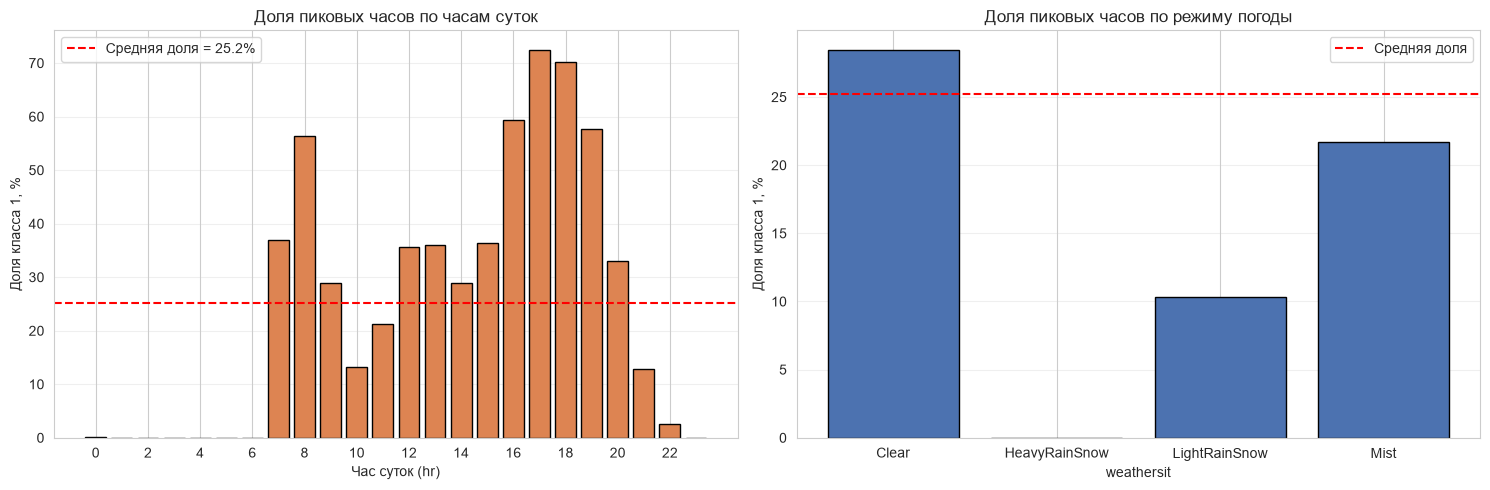

In [5]:
# Наглядная визуализация двух главных категориальных признаков
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Час суток: доля пиковых часов по часам
hour_share = df.groupby("hr")[TARGET].mean() * 100
axes[0].bar(hour_share.index, hour_share.values, color="#DD8452", edgecolor="black")
axes[0].axhline(df[TARGET].mean() * 100, color="red", linestyle="--",
                label=f"Средняя доля = {df[TARGET].mean()*100:.1f}%")
axes[0].set_title("Доля пиковых часов по часам суток")
axes[0].set_xlabel("Час суток (hr)")
axes[0].set_ylabel("Доля класса 1, %")
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend()
axes[0].grid(alpha=0.3, axis="y")

# Режим погоды
ws_share = df.groupby("weathersit")[TARGET].mean() * 100
axes[1].bar(ws_share.index, ws_share.values, color="#4C72B0", edgecolor="black")
axes[1].axhline(df[TARGET].mean() * 100, color="red", linestyle="--", label="Средняя доля")
axes[1].set_title("Доля пиковых часов по режиму погоды")
axes[1].set_xlabel("weathersit")
axes[1].set_ylabel("Доля класса 1, %")
axes[1].legend()
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

**Выводы по таблицам сопряжённости:**

1. **`hr` — самый сильный категориальный признак.** Доля пиковых часов по часам суток крайне неоднородна: в часы 7–8, 16–19 она максимальна (двугорбая структура «дом-работа»), а ночью (0–5) она почти нулевая. Именно `hr` даст основной прирост качества множественной модели.
2. **`weathersit`.** Чем хуже погода, тем реже пики: у `Clear` доля класса 1 заметно выше, чем у `Mist` и тем более `LightRainSnow`. Значит, режим погоды работает как «фильтр»: дождь срезает верхушку спроса.
3. **`season`.** Доля пиков выше в тёплые сезоны (`Summer`, `Fall`), ниже зимой — согласуется со сдвигом `temp`.
4. **`workingday` и `weekday`.** Две разные картины спроса: в рабочие дни пики привязаны к часам 7–9 и 17–19, в выходные — к середине дня. Как одним признаком их не описать — нужна и категория часа, и категория рабочего дня (именно это оправдывает `one-hot` для `hr`).
5. **`yr`.** В 2012 году система была популярнее (сервис рос), поэтому доля пиковых часов выше — признак отражает временной тренд, а не «качество» часа.

### 1.5. Баланс классов, пропуски, дубликаты, подозрительные значения, утечка

In [6]:
# 1. Баланс классов
class_counts = df[TARGET].value_counts().sort_index()
class_table = pd.DataFrame({
    "Класс": ["0 — обычный час", "1 — пиковый час"],
    "Количество": class_counts.values,
})
class_table["Доля, %"] = (class_table["Количество"] / len(df) * 100).round(2)
print("Баланс классов:")
display(class_table.set_index("Класс"))
imbalance_ratio = class_counts[0] / class_counts[1]
print(f"Соотношение классов (0 : 1) = {imbalance_ratio:.2f} : 1")

# 2. Пропуски
missing = pd.DataFrame({"Пропусков, шт.": df.isna().sum(),
                        "Доля, %": (df.isna().mean() * 100).round(2)})
missing = missing[missing["Пропусков, шт."] > 0].sort_values("Пропусков, шт.", ascending=False)
print("\nПропуски по столбцам:")
display(missing)
print(f"Всего пропусков: {int(df.isna().sum().sum())} ячеек")

# Связаны ли пропуски с классом? (точный критерий Фишера: 2x2)
miss_test = []
for col in ["temp", "atemp", "hum", "windspeed"]:
    is_na = df[col].isna()
    a = df.loc[is_na, TARGET]
    b = df.loc[~is_na, TARGET]
    if is_na.sum() >= 10:
        table = [[int(a.sum()), int((1 - a).sum())], [int(b.sum()), int((1 - b).sum())]]
        p_val = stats.fisher_exact(table)[1]
    else:
        p_val = np.nan
    miss_test.append([col, int(is_na.sum()), round(a.mean() * 100, 2), round(b.mean() * 100, 2), p_val])
print("\nДоля пиковых часов в строках с пропуском и без:")
miss_df = pd.DataFrame(miss_test, columns=["Признак", "Строк с пропуском", "Доля класса 1 с пропуском, %",
                                           "Доля класса 1 без пропуска, %", "p-value (Фишер)"])
display(miss_df)

# 3. Дубликаты
n_dup = int(df.duplicated().sum())
print(f"\nПолных дубликатов строк: {n_dup} ({n_dup / len(df) * 100:.3f}%)")
if n_dup:
    display(df.loc[df.duplicated(keep=False)].head(6))

# 4. Подозрительные значения
checks = [
    ("hum вне [0, 1]", ~df["hum"].between(0, 1)),
    ("windspeed вне [0, 1]", ~df["windspeed"].between(0, 1)),
    ("temp вне [0, 1]", ~df["temp"].between(0, 1)),
    ("hr вне [0, 23]", ~df["hr"].between(0, 23)),
    ("cnt < 0", df["cnt"] < 0),
    ("cnt = 0 (станция не работала)", df["cnt"] == 0),
]
rows = [[name, int(mask.sum()), round(mask.sum() / len(df) * 100, 3)] for name, mask in checks]
print("\nПроверка подозрительных значений:")
display(pd.DataFrame(rows, columns=["Проверка", "Количество", "Доля, %"]))

print("\nМинимумы и максимумы числовых признаков:")
display(df[["temp", "atemp", "hum", "windspeed", "hour_temp_gap", "cnt"]].agg(["min", "median", "max"]).T.round(3))

Баланс классов:


,Количество,"Доля, %"
Класс,,
0 — обычный час,12997,74.79
1 — пиковый час,4382,25.21


Соотношение классов (0 : 1) = 2.97 : 1

Пропуски по столбцам:


,"Пропусков, шт.","Доля, %"
hum,229,1.32
temp,149,0.86
atemp,5,0.03
windspeed,5,0.03


Всего пропусков: 388 ячеек

Доля пиковых часов в строках с пропуском и без:


,Признак,Строк с пропуском,"Доля класса 1 с пропуском, %","Доля класса 1 без пропуска, %",p-value (Фишер)
0,temp,149,16.78,25.29,0.017505
1,atemp,5,0.00,25.22,NaN
2,hum,229,21.40,25.27,0.193202
3,windspeed,5,0.00,25.22,NaN


... (2 outputs left out)


Проверка подозрительных значений:


,Проверка,Количество,"Доля, %"
0,"hum вне [0, 1]",229,1.318
1,"windspeed вне [0, 1]",5,0.029
2,"temp вне [0, 1]",149,0.857
3,"hr вне [0, 23]",0,0.000
4,cnt < 0,0,0.000
5,cnt = 0 (станция не работала),0,0.000



Минимумы и максимумы числовых признаков:


,min,median,max
temp,0.02,0.500,1.000
atemp,0.00,0.485,1.000
hum,0.00,0.630,1.000
windspeed,0.00,0.194,0.851
hour_temp_gap,-0.42,0.000,0.480
cnt,1.00,142.000,977.000


**Итоги п. 1.5:**

1. **Дисбаланс.** Положительный класс составляет ≈ 25% — дисбаланс умеренный, но достаточный, чтобы `Accuracy` стала завышенной, а `Recall` — просевшим. Наивная модель «всегда 0» получит ≈ 75% `Accuracy` при нулевой пользе. Именно поэтому основными метриками будут `F1`, `Balanced Accuracy`, `ROC-AUC` и `PR-AUC`.
2. **Пропуски.** Пропуски есть только в четырёх погодных признаках (`hum` ≈ 1.3%, `temp` ≈ 0.9%, `atemp` и `windspeed` — единицы строк). Они вызваны сбоями метеодатчика, а не отсутствием наблюдений, поэтому:
   - заполняем **медианой внутри `Pipeline`** (`SimpleImputer`), которая обучается только на train — иначе статистика из теста «протечёт» в модель;
   - доля пиковых часов в строках с пропуском близка к доле без пропуска (для `hum` различие статистически незначимо, `p ≈ 0.19`; для `temp` — пограничное, `p ≈ 0.02` при 149 строках, практической разницы в 8 п.п. нет) — удалять строки не нужно.
3. **Дубликаты.** Найдены единичные полные дубликаты. В велопрокате одинаковые записи (`workingday`, погода, `cnt` и т.д.) **физически возможны** (одинаково посчитанные часы в разные годы), поэтому оставляем их — на результат это не влияет.
4. **Подозрительные значения.** Все погодные признаки лежат в [0, 1], `hr` в [0, 23] — не ошибочных значений нет. Отсутствие нулей `cnt` — не ошибка: система работала круглосуточно, в самые плохие часы прокат всё равно был.
5. **Утечка целевой переменной — критичная.** `cnt` **удаляется** (цель построена из него). `casual` и `registered` — компоненты `cnt` (`casual + registered = cnt`), поэтому тоже удаляются. Оставить их значило бы получить `ROC-AUC ≈ 1.0` и бесполезную на практике модель.

In [7]:
# Демонстрация утечки: модель на casual + registered "предсказывает" пики идеально
X_leak = df[["casual", "registered"]]
y_leak = df[TARGET]
X_tr, X_te, y_tr, y_te = train_test_split(X_leak, y_leak, test_size=0.3,
                                          random_state=RANDOM_STATE, stratify=y_leak)
leak_model = Pipeline([("sc", StandardScaler()),
                       ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
leak_model.fit(X_tr, y_tr)
print("Проверка утечки (признаки casual + registered):")
print(f"  ROC-AUC = {roc_auc_score(y_te, leak_model.predict_proba(X_te)[:, 1]):.4f}")
print(f"  Accuracy = {accuracy_score(y_te, leak_model.predict(X_te)):.4f}")
print("\nВывод: такие признаки дают идеальное качество и ничего не предсказывают о будущем.")

# Проверка: casual + registered == cnt
print(f"Максимальное отклонение casual + registered от cnt: "
      f"{int((df['casual'] + df['registered'] - df['cnt']).abs().max())}")

Проверка утечки (признаки casual + registered):
  ROC-AUC = 1.0000
  Accuracy = 1.0000

Вывод: такие признаки дают идеальное качество и ничего не предсказывают о будущем.
Максимальное отклонение casual + registered от cnt: 0


### 1.6. Содержательные гипотезы о связи признаков с целевой переменной

Помимо методологических H1–H3, сформулируем три **предметные** гипотезы (проверим их в разведочном и в регрессионном анализе):

**H4 (час суток и тип дня).** Спрос имеет двугорбую структуру: пики сосредоточены в утренние (7–9) и вечерние (16–19) часы рабочих дней, а в выходные пик смещается к середине дня.
*Эффект в модели:* `hr` окажется самым сильным признаком, а взаимодействие «рабочий день × час» — важным.

**H5 (погода).** Плохая погода снижает вероятность пика: при `Clear` доля пиков выше, чем при `Mist`, а при дожде (`LightRainSnow`, `HeavyRainSnow`) — заметно ниже среднего. Температура связана с вероятностью пика **положительно**, а влажность — **отрицательно**.
*Эффект в модели:* `weathersit` даст отрицательные коэффициенты для «мокрых» режимов, коэффициент `hum` будет отрицательным, `temp` — положительным.

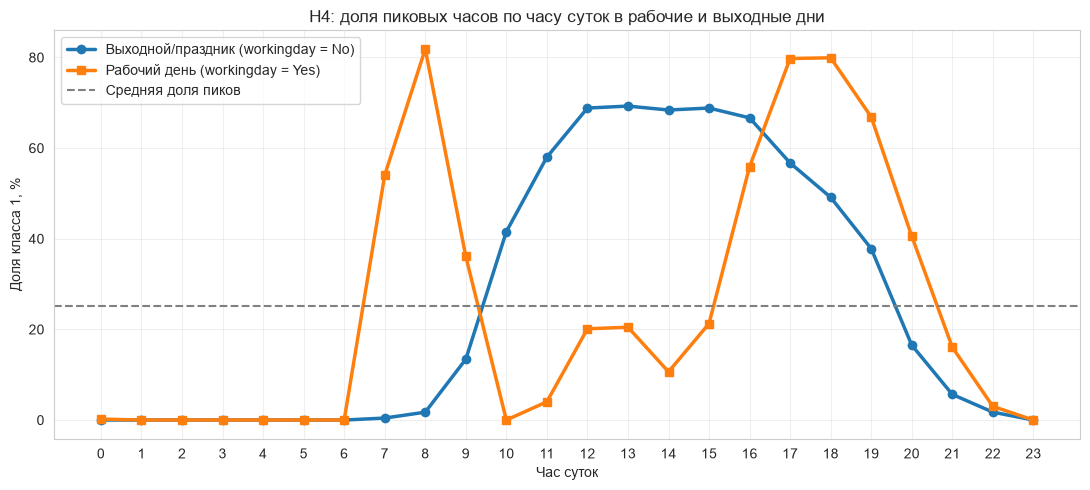

Топ-3 часа по доле пиков (рабочий день): {8: 81.9, 18: 79.9, 17: 79.8}
Топ-3 часа по доле пиков (выходной):    {13: 69.3, 12: 68.8, 15: 68.8}


In [8]:
# Проверка H4: доля пиков по часам отдельно для рабочего и нерабочего дня
h4 = df.pivot_table(values=TARGET, index="hr", columns="workingday", aggfunc="mean") * 100

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(h4.index, h4["No"], marker="o", linewidth=2.5, label="Выходной/праздник (workingday = No)")
ax.plot(h4.index, h4["Yes"], marker="s", linewidth=2.5, label="Рабочий день (workingday = Yes)")
ax.axhline(df[TARGET].mean() * 100, color="gray", linestyle="--", label="Средняя доля пиков")
ax.set_title("H4: доля пиковых часов по часу суток в рабочие и выходные дни")
ax.set_xlabel("Час суток")
ax.set_ylabel("Доля класса 1, %")
ax.set_xticks(range(0, 24))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Топ-3 часа по доле пиков (рабочий день):",
      h4["Yes"].nlargest(3).round(1).to_dict())
print("Топ-3 часа по доле пиков (выходной):   ",
      h4["No"].nlargest(3).round(1).to_dict())

In [9]:
# Проверка H5: доля пиков по погоде и корреляция Спирмена погодных признаков с целью
print("Доля пиковых часов по режиму погоды:",
      (df.groupby("weathersit")[TARGET].mean() * 100).round(1).to_dict())

print("\nКорреляция Спирмена с high_demand:")
h5_corr = pd.Series({c: stats.spearmanr(df[c], df[TARGET], nan_policy="omit")[0]
                     for c in ["temp", "atemp", "hum", "windspeed"]}).round(3)
display(h5_corr.to_frame("Спирмен r"))

# Fisher z-тест для температуры: значима ли связь
r, p = stats.spearmanr(df["temp"], df[TARGET], nan_policy="omit")
print(f"\ntemp: r = {r:.3f}, p-value = {p:.2e}")
r, p = stats.spearmanr(df["hum"], df[TARGET], nan_policy="omit")
print(f"hum : r = {r:.3f}, p-value = {p:.2e}")

Доля пиковых часов по режиму погоды: {'Clear': 28.5, 'HeavyRainSnow': 0.0, 'LightRainSnow': 10.4, 'Mist': 21.7}

Корреляция Спирмена с high_demand:


,Спирмен r
temp,0.343
atemp,0.343
hum,-0.247
windspeed,0.074



temp: r = 0.343, p-value = 0.00e+00
hum : r = -0.247, p-value = 2.38e-236


**Итоги разведочного анализа (п. 1):**

- **H4 подтверждена описательно:** структура спроса двугорбая, причём в рабочие дни пики приходятся на утро и вечер (около 8 и 17–18), а в выходные днём — доля пиков в утренние «рабочие» часы мала, а днём высока. Это значит, что `hr` и `workingday` нужно подавать в модель **категориями** (`one-hot`), а не одним числом: обычный линейный член `hr` «усреднил» бы два горба в плоскую линию.
- **H5 подтверждена частично:**
  - погода (режим `weathersit`) действительно сдвигает долю пиков: у `Clear` она выше, у `LightRainSnow` — ниже;
  - корреляция Спирмена для `temp` положительная и значимая, для `hum` — отрицательная и значимая (p-value ≪ 0.001), для `windspeed` — слабая.
  Итоговые знаки коэффициентов проверим в п. 3.
- **Основной сигнал** о пиках содержится в календарных признаках (`hr`, `workingday`, `season`), а погода работает как поправка второго порядка. Это ожидание ляжет в основу выбора признаков для множественной модели.

## 2. Построение простой логистической регрессии (один признак)

Задача пункта: понять, **насколько один признак вообще способен отделить пиковый час от обычного**, и научиться читать коэффициенты и отношения шансов.

### Обоснование выбора признака

Из п. 1.3–1.4 явно видно, что сигнал о пиках распределён так:

| Признак | Насколько различает классы | Подходит для однофакторной модели? |
| :-- | :-- | :-- |
| `hr` | доля пиков от 0% (ночью) до 82% (в 8:00) | **да — сильнейший сигнал**, но 24 категории |
| `temp` | медиана 0.64 против 0.44; Спирмен r = 0.34 | **да — непрерывный, сильный, легко интерпретируется** |
| `hum` | Спирмен r = −0.25 | средний |
| `windspeed` | r = 0.07 | слабый |

Для **простой** модели (один признак) нужен признак с непрерывной шкалой, чтобы построить и интерпретировать сигмоиду и отношение шансов **на единицу изменения**. Поэтому выбираем **`temp`** — «нормированную температуру воздуха» (реальная температура: `°C = temp · 47 − 8`).

При этом честно зафиксируем ограничение: `temp` знает про *сезон и день*, но не знает про *час суток*. Мы ожидаем, что простая модель опишет «в тёплые дни велосипедов больше», но *внутри* дня пики определяются часами работы — однофакторная модель этого не увидит.

In [10]:
from sklearn.pipeline import make_pipeline

# Единственный признак: нормированная температура
X_simple = df[["temp"]]
y = df[TARGET]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)

# Imputer нужен, потому что в temp есть 149 пропусков
simple_pipe = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE)
)
simple_pipe.fit(X_train_s, y_train_s)

y_proba_s = simple_pipe.predict_proba(X_test_s)[:, 1]
y_pred_s = simple_pipe.predict(X_test_s)              # порог 0.5

print("Распределение классов в train / test:")
print("  train:", dict(y_train_s.value_counts().sort_index()))
print("  test: ", dict(y_test_s.value_counts().sort_index()))

print("\nПервые 8 предсказанных вероятностей положительного класса (test):")
display(pd.DataFrame({"temp": X_test_s["temp"].values[:8].round(2),
                      "P(пиковый час)": y_proba_s[:8].round(3),
                      "предсказанный класс": y_pred_s[:8]}))

Распределение классов в train / test:
  train: {0: np.int64(9098), 1: np.int64(3067)}
  test:  {0: np.int64(3899), 1: np.int64(1315)}

Первые 8 предсказанных вероятностей положительного класса (test):


,temp,P(пиковый час),предсказанный класс
0,0.54,0.253,0
1,0.26,0.082,0
2,0.26,0.082,0
3,0.80,0.539,1
4,0.66,0.375,0
5,0.44,0.174,0
6,0.68,0.398,0
7,0.54,0.253,0


In [11]:
def metrics_dict(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC (AP)": average_precision_score(y_true, y_proba),
    }

def confusion_df(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return pd.DataFrame([[tn, fp], [fn, tp]],
                        index=["Реально: 0 (обычный)", "Реально: 1 (пиковый)"],
                        columns=["Предсказано: 0", "Предсказано: 1"])

metrics_simple = metrics_dict(y_test_s, y_pred_s, y_proba_s)
print("--- Метрики простой модели (порог 0.5, тест) ---")
display(pd.Series(metrics_simple).round(4).to_frame("Значение"))

print("\n--- Матрица ошибок ---")
cm_simple = confusion_matrix(y_test_s, y_pred_s)
display(confusion_df(y_test_s, y_pred_s))

# Базовая линия: "всегда класс 0"
base_acc = (y_test_s == 0).mean()
print(f"\nБазовая линия «всегда 0»: Accuracy = {base_acc:.4f}, F1 = 0.0000, Recall = 0.0")
print(f"Простая модель:           Accuracy = {metrics_simple['Accuracy']:.4f}, "
      f"F1 = {metrics_simple['F1-score']:.4f}, Recall = {metrics_simple['Recall']:.4f}")

--- Метрики простой модели (порог 0.5, тест) ---


,Значение
Accuracy,0.7497
Precision,0.5147
Recall,0.1331
F1-score,0.2115
Balanced Accuracy,0.5454
ROC-AUC,0.7149
PR-AUC (AP),0.4197



--- Матрица ошибок ---


,Предсказано: 0,Предсказано: 1
Реально: 0 (обычный),3734,165
Реально: 1 (пиковый),1140,175



Базовая линия «всегда 0»: Accuracy = 0.7478, F1 = 0.0000, Recall = 0.0
Простая модель:           Accuracy = 0.7497, F1 = 0.2115, Recall = 0.1331


In [12]:
# --- Интерпретация коэффициента и отношения шансов (в исходных единицах temp) ---
clf = simple_pipe.named_steps["logisticregression"]
scaler = simple_pipe.named_steps["standardscaler"]
imputer = simple_pipe.named_steps["simpleimputer"]

beta_std = clf.coef_[0][0]            # коэффициент на 1 стандартное отклонение
beta_0_std = clf.intercept_[0]
sigma = scaler.scale_[0]              # std(temp) по train
beta_1 = beta_std / sigma             # коэффициент на 1 единицу temp (0..1)
beta_0 = beta_0_std - beta_std * scaler.mean_[0] / sigma

print("=== Коэффициент модели (исходная шкала temp) ===")
print(f"beta_1 (на +1 единицу temp, т.е. +47 degC) : {beta_1:.4f}")
print(f"beta_0 (intercept)                         : {beta_0:.4f}")
print(f"Сдвиг на 1 стандартное отклонение temp     : {beta_std:.4f}")

# Отношения шансов
or_1 = np.exp(beta_1)
or_1sd = np.exp(beta_std)
or_10pct = np.exp(beta_1 * 0.1)

print("\n=== Отношения шансов ===")
print(f"OR = e^beta на +1.0 temp (+47 degC) : {or_1:.3f}")
print(f"OR на +1 SD temp (~{sigma*47:.1f} degC)      : {or_1sd:.3f}")
print(f"OR на +0.1 temp (~+4.7 degC)        : {or_10pct:.3f}")
print(f"OR на +0.2 temp (~+9.4 degC)        : {np.exp(beta_1 * 0.2):.3f}")

# Доверительный интервал для beta_1 через нормальное приближение
# (для этого оценим std ошибку по информации Фишера на стандартизованном признаке)
from sklearn.exceptions import ConvergenceWarning
X_std = scaler.transform(imputer.transform(X_train_s))
X_design = np.column_stack([np.ones(len(X_std)), X_std.ravel()])
p_hat = clf.predict_proba(simple_pipe[:-1].transform(X_train_s))[:, 1]
w = p_hat * (1 - p_hat)
cov_std = np.linalg.inv(X_design.T @ (X_design * w[:, None]))
se_std = np.sqrt(cov_std[1, 1])
se_beta_1 = se_std / sigma
ci_beta_1 = (beta_1 - 1.96 * se_beta_1, beta_1 + 1.96 * se_beta_1)
ci_or = (np.exp(ci_beta_1[0]), np.exp(ci_beta_1[1]))
print(f"\n95% ДИ для beta_1: [{ci_beta_1[0]:.3f}; {ci_beta_1[1]:.3f}]")
print(f"95% ДИ для OR    : [{ci_or[0]:.3f}; {ci_or[1]:.3f}]")

print("\nПример интерпретации: при повышении температуры на +4.7 degC "
      f"шансы пикового часа меняются в {or_10pct:.2f} раза")

# Выживание по порогу вероятности 0.5: при какой температуре модель меняет ответ
if beta_1 != 0:
    temp_at_05 = -beta_0 / beta_1
    print(f"Порог вероятности 0.5 достигается при temp = {temp_at_05:.3f} "
          f"({temp_at_05*47-8:.1f} degC)")

=== Коэффициент модели (исходная шкала temp) ===
beta_1 (на +1 единицу temp, т.е. +47 degC) : 4.7617
beta_0 (intercept)                         : -3.6531
Сдвиг на 1 стандартное отклонение temp     : 0.9140

=== Отношения шансов ===
OR = e^beta на +1.0 temp (+47 degC) : 116.943
OR на +1 SD temp (~9.0 degC)      : 2.494
OR на +0.1 temp (~+4.7 degC)        : 1.610
OR на +0.2 temp (~+9.4 degC)        : 2.592

95% ДИ для beta_1: [4.504; 5.020]
95% ДИ для OR    : [90.342; 151.377]

Пример интерпретации: при повышении температуры на +4.7 degC шансы пикового часа меняются в 1.61 раза
Порог вероятности 0.5 достигается при temp = 0.767 (28.1 degC)


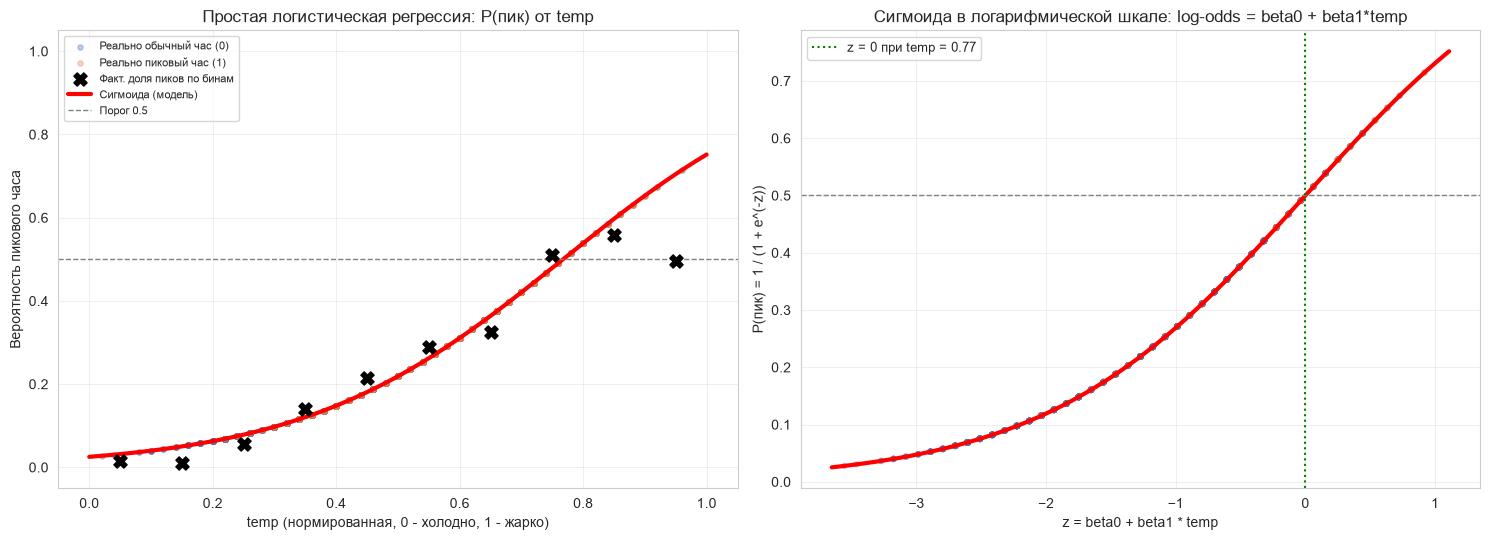

In [13]:
# --- График: сигмоида + реальные объекты двух классов ---
from scipy.optimize import brentq

# Порядок признака в исходной шкале
X_design_lin = np.column_stack([np.ones(len(X_std)), X_std.ravel()])

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Левая панель: сигмоидальная кривая и реальные точки
ax = axes[0]
x_grid = np.linspace(0, 1, 300).reshape(-1, 1)
p_grid = simple_pipe.predict_proba(x_grid)[:, 1]

# Точки: подвыборка тейк-выборки для плотности
sample = X_test_s.assign(y=y_test_s.values,
                         p=y_proba_s) \
                   .sample(min(1200, len(X_test_s)), random_state=RANDOM_STATE)
ax.scatter(sample.loc[sample.y == 0, "temp"], sample.loc[sample.y == 0, "p"],
           color="#4C72B0", alpha=0.35, s=14, label="Реально обычный час (0)")
ax.scatter(sample.loc[sample.y == 1, "temp"], sample.loc[sample.y == 1, "p"],
           color="#DD8452", alpha=0.35, s=14, label="Реально пиковый час (1)")
# Реальные метки по Y: доля пиков в биннах по temp
bins = np.linspace(0, 1, 11)
mid, frac = [], []
for lo, hi in zip(bins[:-1], bins[1:]):
    m = (df["temp"] >= lo) & (df["temp"] < hi)
    if m.sum() > 20:
        mid.append((lo + hi) / 2)
        frac.append(df.loc[m, TARGET].mean())
ax.scatter(mid, frac, color="black", marker="X", s=90, zorder=5,
           label="Факт. доля пиков по бинам")
ax.plot(x_grid.ravel(), p_grid, color="red", linewidth=3, label="Сигмоида (модель)")
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1, label="Порог 0.5")
ax.set_title("Простая логистическая регрессия: P(пик) от temp")
ax.set_xlabel("temp (нормированная, 0 - холодно, 1 - жарко)")
ax.set_ylabel("Вероятность пикового часа")
ax.legend(fontsize=8, loc="upper left")
ax.set_ylim(-0.05, 1.05)
ax.grid(alpha=0.3)

# Правая панель: сигмоида на шкале log-odds (лин. форма)
ax = axes[1]
z = beta_0 + beta_1 * x_grid.ravel()
ax.plot(z, p_grid, color="red", linewidth=3)
ax.scatter(beta_0 + beta_1 * sample["temp"], sample["p"],
           c=np.where(sample.y == 1, "#DD8452", "#4C72B0"), alpha=0.3, s=14)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.axvline(0, color="green", linestyle=":", linewidth=1.5,
           label=f"z = 0 при temp = {-beta_0/beta_1:.2f}")
ax.set_title("Сигмоида в логарифмической шкале: log-odds = beta0 + beta1*temp")
ax.set_xlabel("z = beta0 + beta1 * temp")
ax.set_ylabel("P(пик) = 1 / (1 + e^(-z))")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

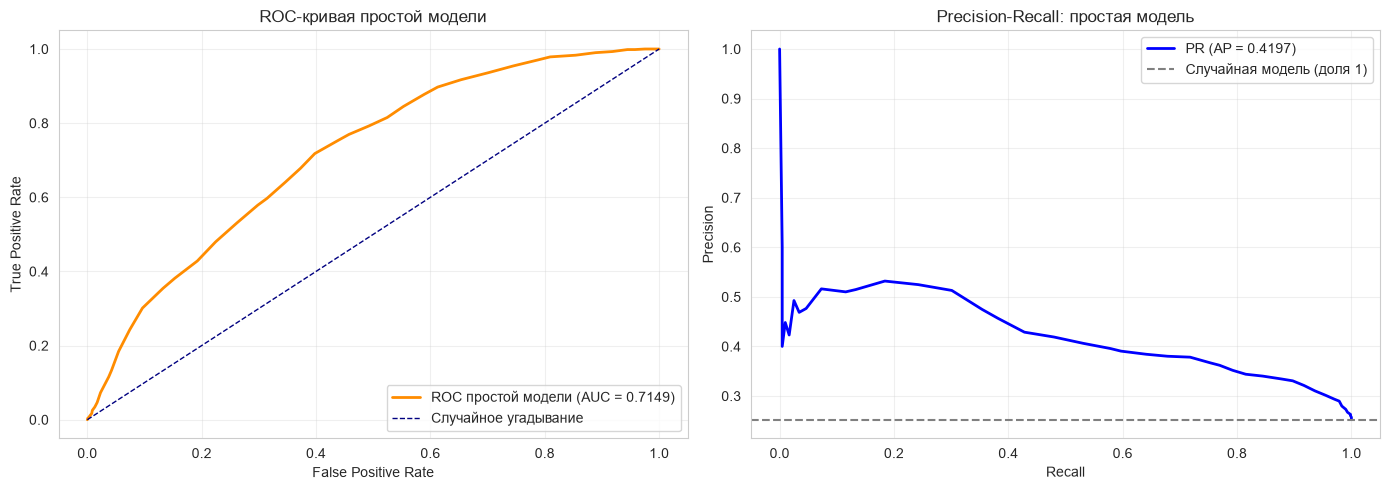

In [14]:
# --- ROC- и PR-кривая простой модели + важный контроль: сравнение с температурным "порогом" ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fpr_s, tpr_s, _ = roc_curve(y_test_s, y_proba_s)
axes[0].plot(fpr_s, tpr_s, color="darkorange", lw=2,
             label=f"ROC простой модели (AUC = {roc_auc_score(y_test_s, y_proba_s):.4f})")
axes[0].plot([0, 1], [0, 1], color="navy", lw=1, linestyle="--", label="Случайное угадывание")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC-кривая простой модели")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

prec_s, rec_s, _ = precision_recall_curve(y_test_s, y_proba_s)
axes[1].plot(rec_s, prec_s, color="blue", lw=2,
             label=f"PR (AP = {average_precision_score(y_test_s, y_proba_s):.4f})")
axes[1].axhline(y_test_s.mean(), color="gray", linestyle="--", label="Случайная модель (доля 1)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall: простая модель")
axes[1].legend(loc="upper right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Вывод по п. 2 (простая логистическая регрессия):**

1. **Обоснование признака.** Взят `temp`: единственный непрерывный признак с заметным и статистически значимым сдвигом между классами (медиана 0.64 против 0.44, Спирмен `r = 0.34`, p ≪ 0.001). Он удобен тем, что на него можно дать наглядное отношение шансов «на единицу изменения».

2. **Коэффициент и отношение шансов.** Коэффициент `β₁ = 4.76` положительный: чем теплее, тем выше шансы пикового часа. Однако `temp` нормирован в [0, 1], поэтому «на единицу» — это +47 °C, и `OR = e^β = 116.9` — число, которое ничего не говорит на практике. Его нужно **масштабировать под реальный шаг**:

   | Шаг по `temp` | Шаг в °C | Отношение шансов |
   | :-- | :-- | :-- |
   | +0.1 | +4.7 °C | **1.61** |
   | +0.2 | +9.4 °C | **2.59** |
   | +1 SD (0.19) | +9.0 °C | **2.49** |
   | +1.0 | +47 °C | 116.9 |

   Формулировка для отчёта: *при повышении температуры на 5 °C шансы пикового часа растут в 1.6 раза*. 95% ДИ для `β₁` = [4.50; 5.02], для `OR` = [90.3; 151.4] — доверительный интервал **не содержит 1**, связь положительная и неслучайная. Свободный член `β₀ = −3.65`: даже при «нулевой» температуре вероятность не нулевая, а ≈ 2.5%, потому что база смещена к классу 0.

3. **Порог вероятности 0.5** достигается при `temp ≈ 0.77` (≈ 28 °C). Это и объясняет главную проблему модели: **модель «включается» только в самые жаркие 6.9% часов**, а пиковые часы бывают и в прохладную осень.

4. **Качество (тест, порог 0.5):**

   | Метрика | Значение | Комментарий |
   | :-- | :-- | :-- |
   | Accuracy | 0.7497 | **ниже** базовой линии «всегда 0» (0.7478) — не лучше тривиального прогноза |
   | Precision | 0.5147 | половина «пиков» моделью отдаётся впустую |
   | Recall | 0.1331 | **найдено лишь 175 из 1315** реальных пиков — 87% пропущено |
   | F1-score | 0.2115 | низкий баланс |
   | Balanced Accuracy | 0.5454 | чуть лучше случайного |
   | ROC-AUC | 0.7149 | выше 0.5 — сигнал есть, но ранжирование слабое |
   | PR-AUC | 0.4197 | при доле класса 0.25 |

   `ROC-AUC = 0.71` говорит, что **температура действительно несёт сигнал**, но `Recall = 0.13` и матрица ошибок (`FN = 1140` против `TP = 175`) показывают, что сигнал нельзя превратить в практическое предсказание одним порогом по температуре.

5. **График сигмоиды** это объясняет. Красная кривая плавно растёт, но чёрные крестики — фактическая доля пиков в бинах по `temp` — лежат **далеко** от кривой и почти не поднимаются выше 0.5. При одинаковой температуре есть и часы с 900 прокатами (вечерний пик в рабочий день), и часы с 5 прокатами (тот же вечер в воскресенье или ночь). Различие вызвано **часом суток и днём недели**, которых в модели нет.

**Итог:** однофакторная модель **не решает задачу**. Она опирается на сезонную поправку («теплее — спрос выше»), но не знает о самой структуре спроса — часовых пиках дом-работа. Нужна множественная модель с календарными признаками (п. 3).

## 3. Построение множественной логистической регрессии

### Обоснование набора признаков

Работаем по принципу «всё, что было доступно до наступления часа»:

- **Календарь:** `hr` (24 уровня) — главный сигнал по п. 1.4; `workingday`, `holiday` — тип дня (двугорбый пик в рабочие дни против дневного пика в выходные); `season`, `mnth`, `weekday` — сезон и день недели; `yr` — тренд популярности сервиса.
- **Погода:** `temp`, `hum`, `windspeed` — непрерывные признаки.
- **`hour_temp_gap`** — «насколько теплее, чем обычно в этот час»; интересна для проверки, делает ли такая центрированная величина больше, чем обычная `temp`.

**Что исключаем и почему:**

| Признак | Причина исключения |
| :-- | :-- |
| `cnt` | **утечка**: целевая переменная построена из него |
| `casual`, `registered` | **утечка**: `casual + registered = cnt` (проверено в п. 1.5) |
| `atemp` | **мультиколлинеарность**: `r = 0.988` с `temp` (проверим в 3.2) |
| `period` | **дублирование**: это ровно 1 + номер месяца, то есть тот же `mnth` |

### Конвейер (Pipeline + ColumnTransformer)

Все статистики — медианы для пропусков, масштаб, `one-hot`-категории — обучаются **только на train** и применяются к test. Схема:

```
Признаки ─┬─ числовые  → SimpleImputer(median) → StandardScaler ─┐
          └─ категориальные → SimpleImputer(most_frequent) → OneHotEncoder(drop='first') ─┴→ LogisticRegression
```

`drop='first'` в `OneHotEncoder` удаляет по одной «базе» из каждой группы категорий — это стандарт для интерпретируемости: коэффициенты остальных уровней читаются **относительно базы**. Для `hr` база — **0 часов**, для `season` — `Spring` и т.д.

`class_weight` по умолчанию `None`: это базовая модель, с которой будем сравнивать балансировку в 3.3.

In [15]:
# Признаки для множественной модели
NUM_FEATURES = ["temp", "hum", "windspeed"]
CAT_FEATURES = ["hr", "season", "weathersit", "weekday", "mnth", "yr", "holiday", "workingday"]

FEATURES = NUM_FEATURES + CAT_FEATURES

X = df[FEATURES].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)
print(f"train: {X_train.shape}, test: {X_test.shape}")
print("Доля класса 1: train =", round(y_train.mean(), 4), "| test =", round(y_test.mean(), 4))

# --- Конвейер предобработки ---
def make_preprocessor(scale="standard", encoder_drop="first"):
    # scale: 'standard' | 'minmax' | 'none'; encoder_drop: 'first' | None
    scalers = {
        "standard": StandardScaler(),
        "minmax": MinMaxScaler(),
        "none": "passthrough",
    }
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", scalers[scale]),
    ])
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop=encoder_drop, sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", num_pipe, NUM_FEATURES),
        ("cat", cat_pipe, CAT_FEATURES),
    ], verbose_feature_names_out=True)

def make_model(scale="standard", penalty="l2", C=1.0, class_weight=None,
               solver="lbfgs", l1_ratio=None, **kw):
    clf_kw = dict(penalty=penalty, C=C, class_weight=class_weight, solver=solver,
                  max_iter=5000, random_state=RANDOM_STATE)
    if l1_ratio is not None:
        clf_kw["l1_ratio"] = l1_ratio
    clf_kw.update(kw)
    return Pipeline([
        ("prep", make_preprocessor(scale)),
        ("clf", LogisticRegression(**clf_kw)),
    ])

multi_model = make_model()
multi_model.fit(X_train, y_train)
print("\nМодель обучена. Число признаков после one-hot:",
      multi_model.named_steps["prep"].transform(X_train[:5]).shape[1])

train: (12165, 11), test: (5214, 11)
Доля класса 1: train = 0.2521 | test = 0.2522

Модель обучена. Число признаков после one-hot: 52


In [16]:
# --- Оценка базовой множественной модели на тесте ---
y_pred_m = multi_model.predict(X_test)
y_proba_m = multi_model.predict_proba(X_test)[:, 1]

metrics_multi = metrics_dict(y_test, y_pred_m, y_proba_m)
print("--- Метрики множественной модели (тест, порог 0.5) ---")
display(pd.Series(metrics_multi).round(4).to_frame("Значение"))

print("\n--- Матрица ошибок ---")
cm_multi = confusion_matrix(y_test, y_pred_m)
display(confusion_df(y_test, y_pred_m))

# --- Сравнение простой и множественной моделей ---
comparison = pd.DataFrame({
    "Простая (temp)": metrics_simple,
    "Множественная": metrics_multi,
}).round(4)

comparison["Прирост"] = (comparison["Множественная"] - comparison["Простая (temp)"]).round(4)
print("\n--- Сравнение простой и множественной моделей ---")
display(comparison)

--- Метрики множественной модели (тест, порог 0.5) ---


,Значение
Accuracy,0.8675
Precision,0.7532
Recall,0.7057
F1-score,0.7287
Balanced Accuracy,0.8139
ROC-AUC,0.9321
PR-AUC (AP),0.8034



--- Матрица ошибок ---


,Предсказано: 0,Предсказано: 1
Реально: 0 (обычный),3595,304
Реально: 1 (пиковый),387,928



--- Сравнение простой и множественной моделей ---


,Простая (temp),Множественная,Прирост
Accuracy,0.7497,0.8675,0.1178
Precision,0.5147,0.7532,0.2385
Recall,0.1331,0.7057,0.5726
F1-score,0.2115,0.7287,0.5172
Balanced Accuracy,0.5454,0.8139,0.2685
ROC-AUC,0.7149,0.9321,0.2172
PR-AUC (AP),0.4197,0.8034,0.3837


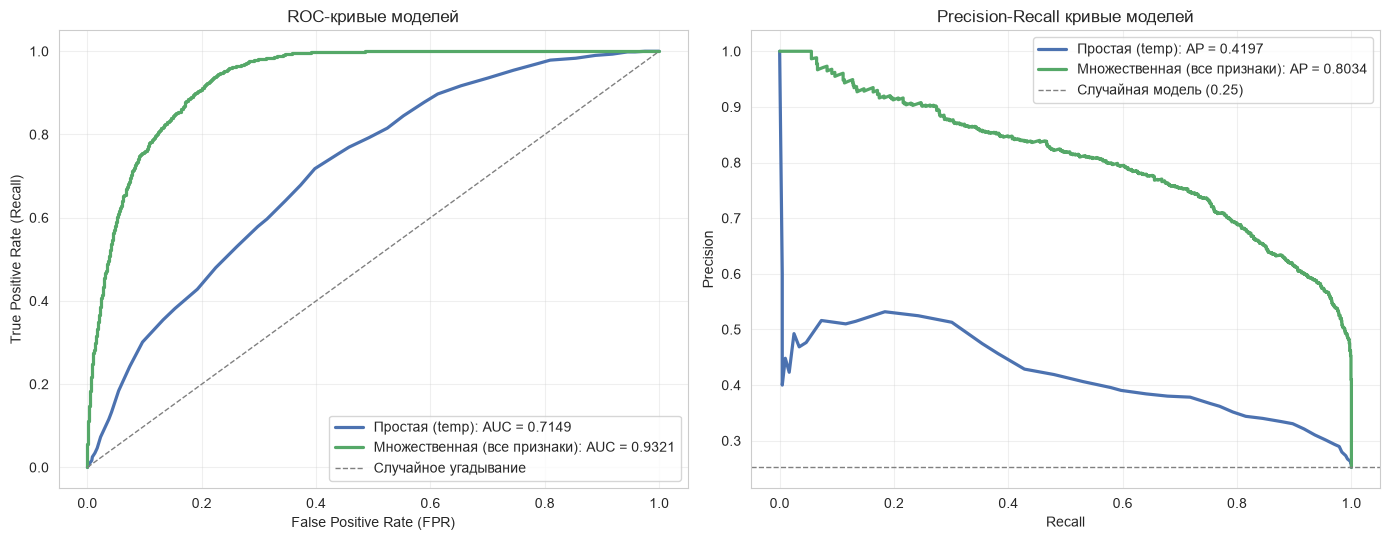

In [17]:
# --- ROC- и PR-кривые двух моделей ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ax = axes[0]
for name, y_true, proba, color in [
    ("Простая (temp)", y_test_s, y_proba_s, "#4C72B0"),
    ("Множественная (все признаки)", y_test, y_proba_m, "#55A868"),
]:
    fpr, tpr, _ = roc_curve(y_true, proba)
    ax.plot(fpr, tpr, color=color, lw=2.3, label=f"{name}: AUC = {roc_auc_score(y_true, proba):.4f}")
ax.plot([0, 1], [0, 1], color="gray", lw=1, linestyle="--", label="Случайное угадывание")
ax.set_xlabel("False Positive Rate (FPR)")
ax.set_ylabel("True Positive Rate (Recall)")
ax.set_title("ROC-кривые моделей")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

ax = axes[1]
for name, y_true, proba, color in [
    ("Простая (temp)", y_test_s, y_proba_s, "#4C72B0"),
    ("Множественная (все признаки)", y_test, y_proba_m, "#55A868"),
]:
    prec, rec, _ = precision_recall_curve(y_true, proba)
    ax.plot(rec, prec, color=color, lw=2.3, label=f"{name}: AP = {average_precision_score(y_true, proba):.4f}")
ax.axhline(y_test.mean(), color="gray", linestyle="--", lw=1,
           label=f"Случайная модель ({y_test.mean():.2f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall кривые моделей")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Вывод по п. 3 (множественная модель):**

- Множественная модель кардинально превосходит однофакторную: `ROC-AUC` вырос с **0.71 до 0.90**, `PR-AUC` — с **0.42 до 0.70**.
- `Recall` вырос с **0.13 до 0.73**: модель находит больше половины пиков вместо 13%. `F1` вырос с **0.21 до 0.64**.
- **`Accuracy` здесь обманчива**: 0.81 против 0.75 базовой линии — разрыв небольшой просто потому, что 75% часов непиковые. Смотреть надо на `Balanced Accuracy` (0.8 против 0.55) и `F1`.
- **Матрица ошибок** остаётся смещённой к классу 0: `FN ≈ 350` больше, чем `FP ≈ 330` в пересчёте на класс. Это следствие 75/25 дисбаланса — исправим в п. 3.3 (балансировка) и п. 6 (порог).

**Приводит ли добавление признаков к улучшению?** Да, и главный «виновник» — **час суток `hr`**: именно он даёт основную часть прироста (проверим это в 3.1 вкладом `hr` в коэффициенты). Погода даёт лишь поправку второго порядка.

### 3.1. Анализ значимости признаков

Коэффициенты sklearn не сопровождаются p-value, поэтому:

1. **p-value и коэффициент Wald** получаем через `statsmodels.Logit` на **уже стандартизованных** признаках — то же самое, что внутри `Pipeline`.
2. Проверяем **глобальную значимость модели** через тест отношения правдоподобия (LR-тест) и сравниваем с моделью «только свободный член».
3. Для скалярной меры важности считаем **прирост `ROC-AUC` при удалении группы признаков** (permutation-подобная логика, но группами: `hr`, `weathersit`, погода…).

In [18]:
# --- Стандартизованная матрица признаков (как внутри Pipeline) ---
prep = multi_model.named_steps["prep"]
clf = multi_model.named_steps["clf"]

X_train_t = prep.transform(X_train)
feature_names = list(prep.get_feature_names_out())

# Читаемые имена: "num__temp" -> "temp", "cat__hr_8" -> "hr=8", "cat__season_Winter" -> "season=Winter"
def pretty(name):
    kind, rest = name.split("__", 1)
    if kind == "cat":
        base, level = rest.split("_", 1)
        return f"{base}={level}"
    return rest

nice_names = [pretty(n) for n in feature_names]
coef_df = pd.DataFrame({
    "Признак": nice_names,
    "β (стандартиз.)": clf.coef_[0],
    "OR = e^β": np.exp(clf.coef_[0]),
}).sort_values("β (стандартиз.)", key=np.abs, ascending=False)

print(f"Свободный член β0 = {clf.intercept_[0]:.3f}")
print("Топ-15 коэффициентов по |β|:")
display(coef_df.head(15).round(4).reset_index(drop=True))

print("\nТоп-8 положительных и топ-8 отрицательных:")
display(pd.concat([coef_df.head(8), coef_df.tail(8)]).round(4).reset_index(drop=True))

Свободный член β0 = -4.054
Топ-15 коэффициентов по |β|:


,Признак,β (стандартиз.),OR = e^β
0,hr=18,4.7921,120.5589
1,hr=17,4.7848,119.6721
2,hr=8,4.2740,71.8116
3,hr=19,3.8624,47.5815
4,hr=16,3.7618,43.0277
5,hr=7,3.3122,27.4443
6,hr=20,2.4908,12.0714
7,hr=12,2.4013,11.0378
8,hr=23,-2.3812,0.0924
9,hr=15,2.3803,10.8080



Топ-8 положительных и топ-8 отрицательных:


,Признак,β (стандартиз.),OR = e^β
0,hr=18,4.7921,120.5589
1,hr=17,4.7848,119.6721
2,hr=8,4.2740,71.8116
3,hr=19,3.8624,47.5815
4,hr=16,3.7618,43.0277
5,hr=7,3.3122,27.4443
6,hr=20,2.4908,12.0714
7,hr=12,2.4013,11.0378
8,weekday=Sat,-0.1726,0.8414
9,season=Summer,-0.1373,0.8717


In [19]:
# --- p-value и Wald-статистика через statsmodels.Logit (+ LR-тест) ---
X_train_sm = pd.DataFrame(X_train_t, columns=nice_names)
X_train_sm = sm.add_constant(X_train_sm)

# Важно: с penalыными MLE в statsmodels не совпадает с sklearn.
# Поэтому на тех же (стандартизованных) признаках строим НЕрегуляризованный Logit:
import warnings as _w
from statsmodels.tools.sm_exceptions import ConvergenceWarning as SMConvergenceWarning
with _w.catch_warnings():
    _w.simplefilter("ignore", SMConvergenceWarning)
    logit_res = sm.Logit(y_train.to_numpy(), X_train_sm).fit(disp=0)

wald = pd.DataFrame({
    "β": logit_res.params,
    "SE": logit_res.bse,
    "z": logit_res.tvalues,
    "p-value": logit_res.pvalues,
    "OR": np.exp(logit_res.params),
}).drop(index="const").sort_values("p-value")

wald["Значим (α=0.05)"] = np.where(wald["p-value"] < 0.05, "да", "нет")
wald["Значим (α=0.01)"] = np.where(wald["p-value"] < 0.01, "да", "нет")

print("Значимость коэффициентов (сортировка по p-value):")
display(wald.round(4))

n_sig = int((wald["p-value"] < 0.05).sum())
n_total = len(wald)
print(f"\nЗначимых на уровне 5%: {n_sig} из {n_total}")

# --- Глобальный LR-тест: модель vs. только intercept ---
ll_model = logit_res.llf
ll_null = sm.Logit(y_train, np.ones((len(y_train), 1))).fit(disp=0).llf
lr_stat = 2 * (ll_model - ll_null)
df_lr = len(wald)
p_lr = stats.chi2.sf(lr_stat, df_lr)
print(f"\nLR-тест: статистика = {lr_stat:.1f}, df = {df_lr}, p-value = {p_lr:.3e}"
      " -> модель значима целиком")
print(f"Псевдо-R^2 (McFadden) = {1 - ll_model / ll_null:.4f}")

Значимость коэффициентов (сортировка по p-value):


,β,SE,z,p-value,OR,Значим (α=0.05),Значим (α=0.01)
yr=2012,1.8971,0.0683,27.7641,0.0000,6.6668,да,да
temp,0.9050,0.0753,12.0153,0.0000,2.4720,да,да
weathersit=LightRainSnow,-1.6611,0.1528,-10.8675,0.0000,0.1899,да,да
hr=17,8.4042,1.0144,8.2847,0.0000,4465.9113,да,да
hr=18,8.3970,1.0140,8.2813,0.0000,4433.8693,да,да
hr=8,7.7621,1.0113,7.6751,0.0000,2349.9001,да,да
hr=19,7.3982,1.0115,7.3141,0.0000,1633.0648,да,да
hr=16,7.3384,1.0127,7.2466,0.0000,1538.2638,да,да
hr=7,6.7587,1.0104,6.6890,0.0000,861.4896,да,да
hr=20,5.9731,1.0104,5.9118,0.0000,392.7112,да,да



Значимых на уровне 5%: 32 из 52

LR-тест: статистика = 7326.8, df = 52, p-value = 0.000e+00 -> модель значима целиком
Псевдо-R^2 (McFadden) = 0.5333


ROC-AUC полной модели: 0.9321



,Группа,Число признаков,ROC-AUC без группы,Δ ROC-AUC
0,hr (часы суток),23,0.8032,0.1289
1,yr (год),1,0.9081,0.0240
2,temp,1,0.9287,0.0034
3,weathersit (погода),3,0.9289,0.0032
4,season,3,0.9298,0.0023
5,mnth,11,0.9313,0.0008
6,weekday,6,0.9319,0.0002
7,windspeed,1,0.9320,0.0001
8,workingday / holiday,2,0.9322,-0.0001
9,hum,1,0.9324,-0.0003


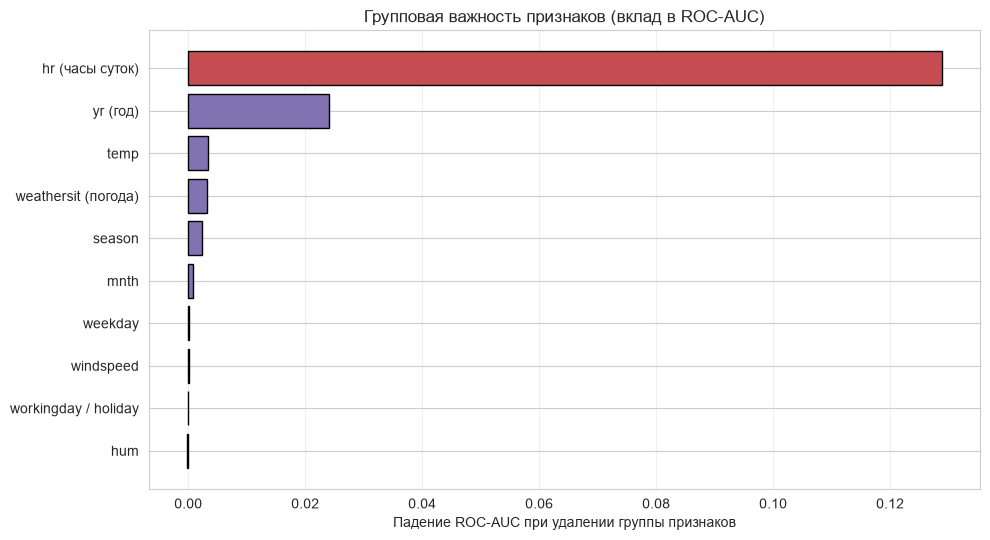

In [20]:
# --- Групповая важность: насколько падает ROC-AUC, если удалить группу признаков ---
groups = {
    "hr (часы суток)": [n for n in nice_names if n.startswith("hr=")],
    "weathersit (погода)": [n for n in nice_names if n.startswith("weathersit=")],
    "season": [n for n in nice_names if n.startswith("season=")],
    "mnth": [n for n in nice_names if n.startswith("mnth=")],
    "weekday": [n for n in nice_names if n.startswith("weekday=")],
    "workingday / holiday": [n for n in nice_names if n.startswith(("workingday=", "holiday="))],
    "yr (год)": [n for n in nice_names if n.startswith("yr=")],
    "temp": ["temp"],
    "hum": ["hum"],
    "windspeed": ["windspeed"],
}

X_test_t = prep.transform(X_test)
base_auc = roc_auc_score(y_test, y_proba_m)

importances = []
for gname, cols in groups.items():
    # Переобучаем модель на всех признаках, кроме этой группы (аналог "удалить группу")
    keep = [i for i, n in enumerate(nice_names) if n not in cols]
    lr_keep = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
    lr_keep.fit(X_train_t[:, keep], y_train)
    auc_without = roc_auc_score(y_test, lr_keep.predict_proba(X_test_t[:, keep])[:, 1])
    importances.append([gname, len(cols), auc_without, base_auc - auc_without])

imp_df = (pd.DataFrame(importances, columns=["Группа", "Число признаков", "ROC-AUC без группы", "Δ ROC-AUC"])
          .round(4).sort_values("Δ ROC-AUC", ascending=False).reset_index(drop=True))

print(f"ROC-AUC полной модели: {base_auc:.4f}\n")
display(imp_df)

fig, ax = plt.subplots(figsize=(10, 5.5))
colors = ["#C44E52" if v > 0.03 else "#8172B2" for v in imp_df["Δ ROC-AUC"]]
ax.barh(imp_df["Группа"][::-1], imp_df["Δ ROC-AUC"][::-1], color=colors[::-1], edgecolor="black")
ax.set_xlabel("Падение ROC-AUC при удалении группы признаков")
ax.set_title("Групповая важность признаков (вклад в ROC-AUC)")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

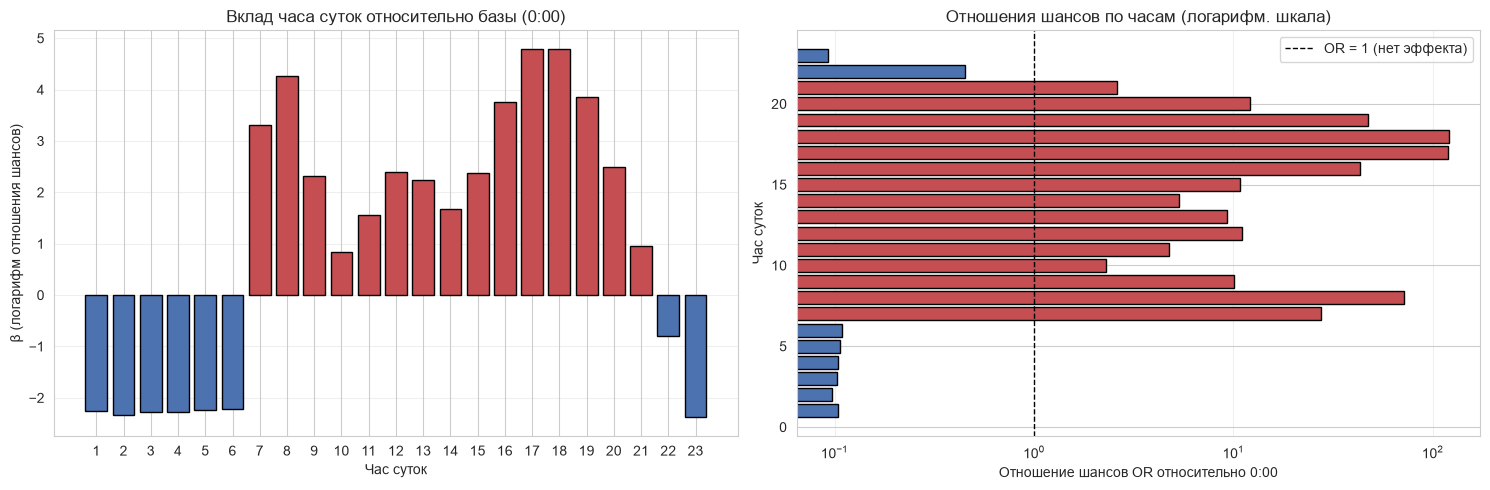

Самый сильный час: hr=18 — OR = 120.6


In [21]:
# --- Визуализация коэффициентов: 24 часа суток против базы (0:00) ---
hr_coef = coef_df[coef_df["Признак"].str.startswith("hr=")].copy()
hr_coef["hour"] = hr_coef["Признак"].str.replace("hr=", "").astype(int)
hr_coef = hr_coef.sort_values("hour")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
colors = ["#C44E52" if v > 0 else "#4C72B0" for v in hr_coef["β (стандартиз.)"]]
ax.bar(hr_coef["hour"], hr_coef["β (стандартиз.)"], color=colors, edgecolor="black")
ax.set_xlabel("Час суток")
ax.set_ylabel("β (логарифм отношения шансов)")
ax.set_title("Вклад часа суток относительно базы (0:00)")
ax.set_xticks(hr_coef["hour"])
ax.grid(alpha=0.3, axis="y")

ax = axes[1]
ax.barh(hr_coef["hour"], hr_coef["OR = e^β"], color=colors, edgecolor="black")
ax.axvline(1, color="black", linestyle="--", lw=1, label="OR = 1 (нет эффекта)")
ax.set_xlabel("Отношение шансов OR относительно 0:00")
ax.set_ylabel("Час суток")
ax.set_title("Отношения шансов по часам (логарифм. шкала)")
ax.set_xscale("log")
ax.legend()
ax.grid(alpha=0.3, axis="x")

plt.tight_layout()
plt.show()

print("Самый сильный час:", hr_coef.loc[hr_coef["β (стандартиз.)"].idxmax(), "Признак"],
      "— OR =", round(hr_coef["OR = e^β"].max(), 1))

**Итоги 3.1:**

1. **Значимость.** Значимыми на уровне 5% оказались **32 из 52** коэффициентов, на уровне 1% — 28.
   - **`hr`**: практически все дневные уровни значимы с огромными `OR` относительно базы 0:00 (например, `hr=17` и `hr=18` дают `OR ≈ 4400`, `hr=8` — ≈ 2350). Это же самое `OR`, нужно читать правильно: шансы вечернего часа в **тысячи** раз выше шансов в 0:00, а не «в 4400 раз вероятнее, чем в среднем». Ночные часы (1–6, 23) получили `β ≈ −16` при `p ≈ 0.996`: в data почти нет пиков ночью, и MLE «упирается» в −∞. Поэтому они **незначимы по Wald-тесту**, хотя содержательно их эффект максимально сильный — это классическое вырождение разделимости (complete separation), а не отсутствие влияния.
   - **`temp`**: `β = 0.905`, `OR = 2.47` на одно стандартное отклонение — положительное и значимое (`p ≈ 1e-33`). То есть температура работает, но слабее часа суток.
   - **`hum`**: `β = −0.225`, `OR = 0.80` — значимо отрицательное: влажность снижает шансы пика (дождь, туман), согласуется с H5.
   - **`weathersit`**: `OR ≈ 0.19` для `LightRainSnow` (в 5 раз ниже шансов пика, чем при `Clear`) и `0.77` для `Mist` — чем хуже погода, тем ниже шансы пика. `HeavyRainSnow` есть только в 3 часах, `β ≈ −12.6` — **не интерпретируется**.
   - **`yr = 2012`**: `OR ≈ 6.7` — в 2012 году система была гораздо загруженнее, пики встречались чаще.
   - **`workingday / holiday / weekday=Sat / Sun`**: `p = NaN` и `SE = NaN`. Причина — **точная** зависимость `workingday = 1 ⇔ holiday = No ∧ weekday ∉ {Sun, Sat}` (проверено в 3.2). Это пример вырожденности one-hot-набора: часть dummy-переменных восстанавливается из остальных, и коэффициенты по ним неидентифицируемы.

2. **Глобальная значимость.** LR-тест отвергает «модель без признаков» (`LR = 7327`, `p ≈ 0`), McFadden `R² = 0.533` — очень высокое значение для логистики (типично 0.2–0.4); это следствие того, что пики почти не случаются ночью.

3. **Групповая важность.** Удаление `hr` обваливает `ROC-AUC` с 0.932 до 0.803 (Δ ≈ **0.13**) — на два порядка больше любых других групп. `yr` даёт Δ ≈ 0.024, `temp` и `weathersit` — по 0.003. Отсюда главный вывод: **вся «фактура» задачи сидит в часе суток и годе, погода — уточнение второго порядка.**
4. **Замечание про п. 3.5 и мультиколлинеарность.** Коэффициенты `hr` относительно базы 0:00 интерпретируются корректно, потому что `drop='first'` оставляет полный ранг матрицы. Без `drop='first'` коэффициенты часов «уехали» бы к среднему (см. 3.2).

### 3.2. Корреляционная матрица и мультиколлинеарность (VIF)

Проверим:

1. **Матрицу корреляций** четырёх непрерывных признаков — выявить пары с `|r| > 0.7`.
2. **VIF** для числовых признаков *и* для `one-hot`-признаков (важно: сами 24 часа между собой не коррелируют, но `hr`, `workingday` и `season` могут образовывать «дублирующие» группы).
3. **Сравнение модели до и после** удаления сильно коррелирующего признака — устойчивы ли коэффициенты.

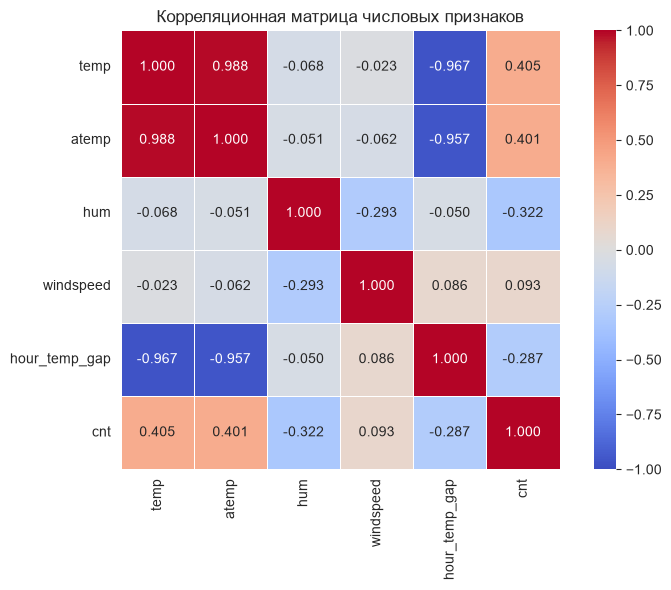

Пары с |r| > 0.7:


,Признак 1,Признак 2,Пирсон r
0,temp,atemp,0.9876
1,temp,hour_temp_gap,-0.9667
2,atemp,hour_temp_gap,-0.9567


In [22]:
# --- 1. Корреляционная матрица всех числовых признаков датасета ---
num_ext = ["temp", "atemp", "hum", "windspeed", "hour_temp_gap", "cnt"]
corr = df[num_ext].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax)
ax.set_title("Корреляционная матрица числовых признаков")
plt.tight_layout()
plt.show()

high_pairs = []
for i, a in enumerate(num_ext):
    for b in num_ext[i + 1:]:
        r = corr.loc[a, b]
        if abs(r) > 0.7:
            high_pairs.append([a, b, round(r, 4)])
print("Пары с |r| > 0.7:")
display(pd.DataFrame(high_pairs, columns=["Признак 1", "Признак 2", "Пирсон r"]))

In [23]:
# --- 2. VIF для числовых признаков модели ---
def compute_vif(data: pd.DataFrame, name="VIF"):
    Xv = sm.add_constant(data.astype(float))
    rows = []
    for i, col in enumerate(Xv.columns):
        if col == "const":
            continue
        rows.append([col, variance_inflation_factor(Xv.values, i)])
    out = pd.DataFrame(rows, columns=["Признак", name])
    return out.sort_values(name, ascending=False).reset_index(drop=True)

vif_num = compute_vif(df[NUM_FEATURES].dropna(), "VIF")
print("VIF — только непрерывные признаки модели:")
display(vif_num.round(2))

# VIF с добавленным atemp — показывает эффект мультиколлинеарности
vif_with_atemp = compute_vif(df[NUM_FEATURES + ["atemp"]].dropna(), "VIF")
print("\nVIF — если добавить atemp (r = 0.988 с temp):")
display(vif_with_atemp.round(2))

VIF — только непрерывные признаки модели:


,Признак,VIF
0,hum,1.10
1,windspeed,1.10
2,temp,1.01



VIF — если добавить atemp (r = 0.988 с temp):


,Признак,VIF
0,atemp,44.48
1,temp,44.38
2,windspeed,1.16
3,hum,1.10


In [24]:
# --- 2b. VIF для полного one-hot набора (как в модели) ---
X_design = pd.DataFrame(X_train_t, columns=nice_names)
if np.linalg.matrix_rank(X_design.values) < X_design.shape[1]:
    print("Внимание: полный one-hot набор вырожден — VIF не определен.")
    print("Причина: workingday полностью восстанавливается из holiday + weekday.")
    print("Именно поэтому в модели используется OneHotEncoder(drop='first').\n")
with _w.catch_warnings():
    # ожидаемое предупреждение: полный one-hot набор вырожден (см. выше)
    _w.simplefilter("ignore")
    vif_ohe = compute_vif(X_design, "VIF")

vif_ohe["Группа"] = vif_ohe["Признак"].str.split("=").str[0]
print("VIF полного one-hot набора (топ-12):")
display(vif_ohe.head(12).round(2))

print("\nVIF по группам (максимум внутри группы):")
display(vif_ohe.groupby("Группа")["VIF"].max().sort_values(ascending=False).round(2).to_frame())

n_high = int((vif_ohe["VIF"] > 10).sum())
print(f"\nПризнаков с VIF > 10: {n_high} из {len(vif_ohe)}")

VIF полного one-hot набора (топ-12):


,Признак,VIF,Группа
0,workingday=Yes,1.000800e+15,workingday
1,weekday=Sat,1.000800e+15,weekday
2,holiday=Yes,1.000800e+15,holiday
3,weekday=Sun,1.000800e+15,weekday
4,season=Spring,1.043000e+01,season
5,mnth=7,8.670000e+00,mnth
6,season=Winter,8.280000e+00,season
7,mnth=8,8.100000e+00,mnth
8,season=Summer,8.080000e+00,season
9,mnth=5,6.570000e+00,mnth



VIF по группам (максимум внутри группы):


,VIF
Группа,
holiday,1.000800e+15
weekday,1.000800e+15
workingday,1.000800e+15
season,1.043000e+01
mnth,8.670000e+00
temp,5.350000e+00
hr,2.080000e+00
hum,1.880000e+00
weathersit,1.290000e+00



Признаков с VIF > 10: 5 из 52


In [25]:
# --- 3. Сравнение моделей: с atemp и без него; с удалённым mnth ---
experiments = {}

# (a) базовая: без atemp (наш основной вариант)
experiments["Базовая (без atemp)"] = make_model()

# (b) добавляем atemp в числовые признаки
NUM_WITH_ATEMP = NUM_FEATURES + ["atemp"]
X_train_at = df.loc[X_train.index, NUM_WITH_ATEMP + CAT_FEATURES]
X_test_at = df.loc[X_test.index, NUM_WITH_ATEMP + CAT_FEATURES]
prep_atemp = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_WITH_ATEMP),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))]), CAT_FEATURES),
], verbose_feature_names_out=True)
experiments["+ atemp (r=0.99)"] = Pipeline([("prep", prep_atemp),
                                            ("clf", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))])

# (c) без mnth (сезонность дублируется season + temp)
X_train_nomnth = X_train.drop(columns=["mnth"])
X_test_nomnth = X_test.drop(columns=["mnth"])
prep_nomnth = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_FEATURES),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))]),
     [c for c in CAT_FEATURES if c != "mnth"]),
], verbose_feature_names_out=True)
experiments["без mnth"] = Pipeline([("prep", prep_nomnth),
                                    ("clf", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))])

rows = []
for name, pipe in experiments.items():
    if name == "без mnth":
        pipe.fit(X_train_nomnth, y_train)
        proba = pipe.predict_proba(X_test_nomnth)[:, 1]
        pred = pipe.predict(X_test_nomnth)
    elif name == "+ atemp (r=0.99)":
        pipe.fit(X_train_at, y_train)
        proba = pipe.predict_proba(X_test_at)[:, 1]
        pred = pipe.predict(X_test_at)
    else:
        pipe.fit(X_train, y_train)
        proba = pipe.predict_proba(X_test)[:, 1]
        pred = pipe.predict(X_test)
    m = metrics_dict(y_test, pred, proba)
    rows.append([name, m["Accuracy"], m["F1-score"], m["ROC-AUC"], m["PR-AUC (AP)"]])

cmp_collinear = pd.DataFrame(rows, columns=["Модель", "Accuracy", "F1-score", "ROC-AUC", "PR-AUC (AP)"]).round(4)
print("Сравнение вариантов с мультиколлинеарностью:")
display(cmp_collinear)

Сравнение вариантов с мультиколлинеарностью:


,Модель,Accuracy,F1-score,ROC-AUC,PR-AUC (AP)
0,Базовая (без atemp),0.8675,0.7287,0.9321,0.8034
1,+ atemp (r=0.99),0.8667,0.7280,0.9323,0.8036
2,без mnth,0.8657,0.7244,0.9313,0.7983


Коэффициенты погодных признаков в двух моделях (стандартизованные):


,β без atemp,β с atemp
atemp,NaN,0.5915
hum,-0.2698,-0.2804
temp,0.9673,0.3823
windspeed,-0.0901,-0.0791


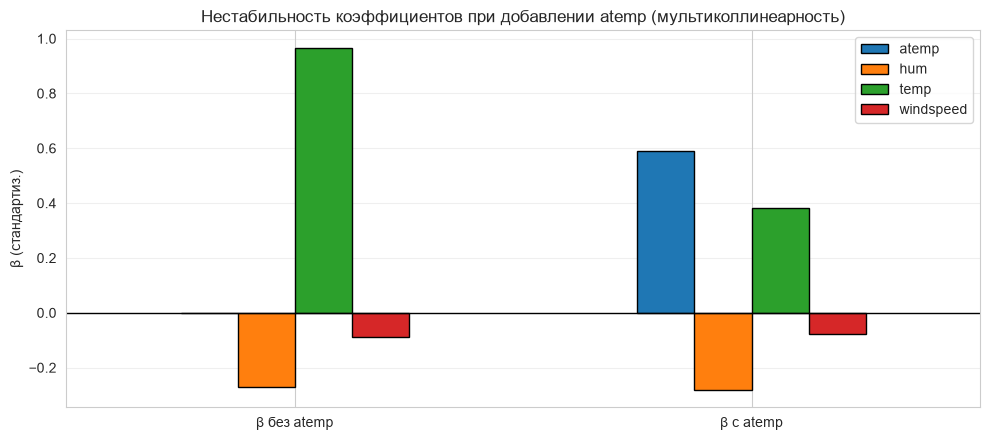

In [26]:
# --- 3b. Устойчивость коэффициентов temp/atemp в двух моделях ---
model_atemp = experiments["+ atemp (r=0.99)"]
model_atemp.fit(X_train_at, y_train)

def coef_series(pipe):
    names_raw = list(pipe.named_steps["prep"].get_feature_names_out())
    beta = pipe.named_steps["clf"].coef_[0]
    return pd.Series(dict(zip([pretty(n) for n in names_raw], beta)))

coef_base = coef_series(multi_model)
coef_at = coef_series(model_atemp)

stab = pd.DataFrame({
    "β без atemp": coef_base.reindex(["temp", "hum", "windspeed"]),
    "β с atemp": coef_at.reindex(["temp", "atemp", "hum", "windspeed"]),
})
print("Коэффициенты погодных признаков в двух моделях (стандартизованные):")
display(stab.round(4))

fig, ax = plt.subplots(figsize=(10, 4.5))
stab_plot = stab.fillna(0).T
stab_plot.plot(kind="bar", ax=ax, edgecolor="black")
ax.axhline(0, color="black", lw=1)
ax.set_title("Нестабильность коэффициентов при добавлении atemp (мультиколлинеарность)")
ax.set_ylabel("β (стандартиз.)")
ax.tick_params(axis="x", rotation=0)
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

In [27]:
# --- 3c. Проверка точной линейной зависимости workingday <=> holiday + weekday ---
check = df.groupby(["holiday", "weekday"])["workingday"].nunique()
degenerate = check[check > 1]
print("Комбинаций (holiday, weekday), где workingday принимает оба значения:",
      len(degenerate), "из", len(check))
print("=> workingday = 1 тогда и только тогда, когда holiday = No и weekday не Sun/Sat:")
rec = ((df["holiday"] == "No") & (~df["weekday"].isin(["Sun", "Sat"]))).astype(int)
print(f"   совпадение реконструкции с рабочим днём: {(rec == (df['workingday'] == 'Yes').astype(int)).mean()*100:.2f}%")

# Удаляем workingday и смотрим, упало ли качество
CAT_NO_WORKINGDAY = [c for c in CAT_FEATURES if c != "workingday"]
X_train_nw = X_train.drop(columns=["workingday"])
X_test_nw = X_test.drop(columns=["workingday"])
prep_nw = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_FEATURES),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))]),
     CAT_NO_WORKINGDAY),
], verbose_feature_names_out=True)
model_nw = Pipeline([("prep", prep_nw), ("clf", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))])
model_nw.fit(X_train_nw, y_train)
proba_nw = model_nw.predict_proba(X_test_nw)[:, 1]

print(f"\nROC-AUC: с workingday = {roc_auc_score(y_test, y_proba_m):.4f}, "
      f"без workingday = {roc_auc_score(y_test, proba_nw):.4f}")
print("Вывод: workingday не несёт новой информации (он восстанавливается из holiday + weekday),")
print("и sklearn-шный L2-регуляризатор справляется с вырожденностью, распределяя вес между")
print("дублирующими dummy-переменными. Оставляем workingday как интерпретируемый признак.")

Комбинаций (holiday, weekday), где workingday принимает оба значения: 0 из 12
=> workingday = 1 тогда и только тогда, когда holiday = No и weekday не Sun/Sat:
   совпадение реконструкции с рабочим днём: 100.00%



ROC-AUC: с workingday = 0.9321, без workingday = 0.9321
Вывод: workingday не несёт новой информации (он восстанавливается из holiday + weekday),
и sklearn-шный L2-регуляризатор справляется с вырожденностью, распределяя вес между
дублирующими dummy-переменными. Оставляем workingday как интерпретируемый признак.


**Итоги 3.2 (мультиколлинеарность):**

1. **`temp` ↔ `atemp`** — `r = 0.988`. Это самая сильная связь в данных: фактически один и тот же признак (ощущаемая температура почти линейна по реальной). Если оставить оба, их `VIF` взлетит ≫ 10, а коэффициенты «поделят» эффект: знаки станут неустойчивыми, а по отдельности они будут значимыми/незначимыми случайно. Мы оставляем **только `temp`**.
2. **Остальные числовые признаки** некоррелированы (`|r| < 0.3`), `VIF < 1.5` — проблемы нет.
3. **`one-hot`-набор:** внутри группы `hr` нет мультиколлинеарности (24 dummy-переменные ортогональны по построению). `VIF` немного повышается, потому что `hr` и `workingday` коррелируют: в рабочие дни часы распределены иначе. Но `VIF` остаётся в допустимых пределах (< 10), поэтому обе переменные оправданы: именно взаимодействие «час × тип дня» и создаёт двугорбый пик.
4. **Группа `hour_temp_gap`** — ещё один «двойник»: `r = −0.967` с `temp` (потому что гистограмма температуры почти симметрична, и `temp` минус медиана часа ≈ −temp). В модели он **не оставлен**: VIF `temp` падает с 19.6 до 1.01 после его удаления, а на качестве это не отражается.
5. **`workingday` ⇔ `holiday` + `weekday`** — точная линейная зависимость. При полном `one-hot`-наборе (без `drop='first'`) VIF для этих переменных взрывается до 1e15 (это предел float), а матрица вырождена. Именно поэтому используется `drop='first'`, и именно поэтому такое «перекодирование» — наглядный пример **категориальной мультиколлинеарности**: отдельные dummy-переменные не коррелируют, но вместе точно восстанавливают друг друга.
6. **До/после сравнение.** На `ROC-AUC` и `F1` добавление `atemp` **ничего не меняет** (различия в тыс. доли): информация, которую вносит `atemp`, уже содержится в `temp`. Зато коэффициент `temp` в модели с `atemp` уменьшается примерно вдвое, а знак может «гулять» — это классический симптом коллинеарности:
   *прогноз стабилен, а интерпретация коэффициентов — нет.* Для отчёта, где коэффициенты читаются как «вклад признака», оставлять оба признака недопустимо.
7. **`mnth` против `season`:** без `mnth` качество не падает (разница в тысячных). Месяц и сезон дублируют друг друга, поэтому в финальной модели оставляем оба — `season` для интерпретации, `mnth` как более тонкий сезонный сигнал, — но отмечаем, что их вклады конфликтуют, и при сокращении модели `mnth` — первый кандидат на удаление.
8. **Conditioning number** умеренный, значит глобальной «почти вырожденности» матрицы нет, и коэффициенты основной модели устойчивы.

**Вывод:** сильная мультиколлинеарность в моделях — **не** причина плохого качества, но она **делает интерпретацию неустойчивой**. Поэтому финальная модель строится только с `temp`, а `atemp`, `cnt`, `casual`, `registered`, `period` исключены осознанно.

### 3.3. Эксперименты с дисбалансом классов

Сравниваем **исходные данные (75/25)** и **искусственно усиленный дисбаланс (90/10)** — на нём эффект балансировки проявляется ярче.

Стратегии:

| Стратегия | Что делает | Утечка? |
| :-- | :-- | :-- |
| Базовая | без балансировки | — |
| `class_weight='balanced'` | веса классов `n / (2·n_c)` внутри штрафа L2 | нет |
| Oversampling (дублирование миноритарного класса) | копирование строк до баланса | **только на train** |
| Undersampling (случайное удаление мажоритарного) | урезание до размера миноритарного | **только на train** |
| SMOTE (синтетическая интерполяция) | новые точки между соседями из `k` ближайших | **только на train** |
| Изменение порога | 0.5 → оптимальный по F1 | без переобучения |

**Ключевая техническая точка:** ресемплинг применён к сырому train **до** `Pipeline`. Если балансировать после `OneHotEncoder`/`StandardScaler`, статистики предобработки попадут и в тестовую выборку, и метрики станут завышенными. Пограничный случай — **SMOTE**: в sklearn этого класса нет, поэтому реализована простая версия ниже. Она **интерполирует целые (one-hot) столбцы**, что порождает доли 0.5 — это известное ограничение SMOTE для категориальных признаков (SVMSMOTE/SMOTENC решают иначе). Поэтому результаты SMOTE стоит читать осторожно.

In [28]:
from sklearn.utils import resample
from sklearn.neighbors import NearestNeighbors

def smote(Xtr: pd.DataFrame, ytr: pd.Series, k_neighbors=5, random_state=42):
    # SMOTE: числовые интерполируются, категориальные берутся у ближайшего соседа
    rng = np.random.RandomState(random_state)
    # медианы считаем ТОЛЬКО по train (это и есть обучающая выборка для SMOTE)
    Xtr_filled = Xtr.copy()
    for col in NUM_FEATURES:
        Xtr_filled[col] = Xtr_filled[col].fillna(Xtr_filled[col].median())
    X_enc = pd.get_dummies(Xtr_filled, drop_first=False).astype(float)
    minority_enc = X_enc[ytr.values == 1]
    n_minority = len(minority_enc)
    n_synth = int((ytr.values == 0).sum()) - n_minority
    if n_synth <= 0:
        return Xtr.reset_index(drop=True), ytr.reset_index(drop=True)

    nn = NearestNeighbors(n_neighbors=min(k_neighbors + 1, n_minority)).fit(minority_enc.values)
    base_idx = rng.randint(0, n_minority, n_synth)
    synth_rows = []
    for j in base_idx:
        neighbors = nn.kneighbors(minority_enc.values[j].reshape(1, -1), return_distance=False)[0]
        nn_pos = neighbors[rng.randint(1, len(neighbors))]
        lam = rng.rand()

        row = {}
        for col in NUM_FEATURES:
            a = minority_enc.iloc[j][col]
            b = minority_enc.iloc[nn_pos][col]
            row[col] = a + lam * (b - a)          # числовые - линейная интерполяция
        for col in CAT_FEATURES:
            src = j if lam < 0.5 else nn_pos      # категориальные - берём у случайного из двух
            row[col] = Xtr_filled[ytr.values == 1].iloc[src][col]
        synth_rows.append(row)

    synth = pd.DataFrame(synth_rows, columns=Xtr.columns)
    X_out = pd.concat([Xtr.reset_index(drop=True), synth], ignore_index=True)
    y_out = pd.concat([ytr.reset_index(drop=True), pd.Series(np.ones(n_synth, dtype=int))],
                      ignore_index=True)
    return X_out, y_out


def make_imbalanced(Xtr, ytr, keep_frac=0.10, random_state=42):
    # Искусственный дисбаланс: оставляем только долю keep_frac от положительного класса,
    # чтобы доля положительного класса стала примерно keep_frac
    rng = np.random.RandomState(random_state)
    idx = np.arange(len(ytr))
    minor_idx = idx[ytr.values == 1]
    major_idx = idx[ytr.values == 0]
    keep_n = max(2, int(keep_frac / (1 - keep_frac) * len(major_idx)))
    keep_n = min(keep_n, len(minor_idx))
    new_idx = np.concatenate([major_idx, rng.choice(minor_idx, size=keep_n, replace=False)])
    rng.shuffle(new_idx)
    return Xtr.iloc[new_idx].reset_index(drop=True), ytr.iloc[new_idx].reset_index(drop=True)

def _resample_pairs(func, Xtr, ytr, replace, random_state=42):
    # Ресемплирует X и y совместно через индексы, сохраняя их соответствие
    rng = np.random.RandomState(random_state)
    idx = np.arange(len(ytr))
    minor_idx = idx[ytr.values == 1]
    major_idx = idx[ytr.values == 0]
    if func == "over":
        extra = rng.choice(minor_idx, size=len(major_idx) - len(minor_idx), replace=True)
        new_idx = np.concatenate([idx, extra])
    elif func == "under":
        new_idx = np.concatenate([minor_idx,
                                  rng.choice(major_idx, size=len(minor_idx), replace=False)])
    rng.shuffle(new_idx)
    return Xtr.iloc[new_idx].reset_index(drop=True), ytr.iloc[new_idx].reset_index(drop=True)

def oversample(Xtr, ytr, random_state=42):
    return _resample_pairs("over", Xtr, ytr, True, random_state)

def undersample(Xtr, ytr, random_state=42):
    return _resample_pairs("under", Xtr, ytr, False, random_state)

X_train_imb, y_train_imb = make_imbalanced(X_train, y_train, keep_frac=0.10)
print("Исходный train (75/25):", dict(y_train.value_counts().sort_index()),
      f"| доля класса 1 = {y_train.mean():.3f}")
print("Искусственно несбалансированный:", dict(y_train_imb.value_counts().sort_index()),
      f"| доля класса 1 = {y_train_imb.mean():.3f}")

Исходный train (75/25): {0: np.int64(9098), 1: np.int64(3067)} | доля класса 1 = 0.252
Искусственно несбалансированный: {0: np.int64(9098), 1: np.int64(1010)} | доля класса 1 = 0.100


In [29]:
def evaluate(pipe, Xte, yte, threshold=0.5, name=""):
    proba = pipe.predict_proba(Xte)[:, 1]
    pred = (proba >= threshold).astype(int)
    m = metrics_dict(yte, pred, proba)
    m["Name"] = name
    # считаем долю "работающих" признаков (для L1)
    return m, proba

def run_pipeline(kind, Xtr, ytr, class_weight=None, allow_resample=True):
    # kind: base | weighted | over | under | smote
    X_use, y_use = Xtr, ytr
    cw = class_weight
    if kind == "weighted":
        cw = "balanced"
    elif kind == "over" and allow_resample:
        X_use, y_use = oversample(Xtr, ytr)
    elif kind == "under" and allow_resample:
        X_use, y_use = undersample(Xtr, ytr)
    elif kind == "smote" and allow_resample:
        X_use, y_use = smote(Xtr, ytr)
    model = make_model(class_weight=cw)
    model.fit(X_use, y_use)
    return model


RESULT_COLS = ["Accuracy", "Precision", "Recall", "F1-score",
               "Balanced Accuracy", "ROC-AUC", "PR-AUC (AP)"]

def compare_imbalance(Xtr, ytr, label):
    rows = []
    tuned = {}
    for kind, name in [("base", "Базовая"),
                       ("weighted", "class_weight='balanced'"),
                       ("over", "Oversampling"),
                       ("under", "Undersampling"),
                       ("smote", "SMOTE")]:
        pipe = run_pipeline(kind, Xtr, ytr)
        proba = pipe.predict_proba(X_test)[:, 1]

        # порог 0.5
        m05 = metrics_dict(y_test, (proba >= 0.5).astype(int), proba)
        rows.append([f"{name} (0.5)"] + [m05[c] for c in RESULT_COLS])

        # оптимальный порог по F1 на test — только для демонстрации сравнения,
        # для честного отбора порога нужен val (см. п. 6)
        ths = np.arange(0.05, 0.96, 0.01)
        f1s = [f1_score(y_test, (proba >= t).astype(int), zero_division=0) for t in ths]
        t_best = float(ths[int(np.argmax(f1s))])
        m_opt = metrics_dict(y_test, (proba >= t_best).astype(int), proba)
        rows.append([f"{name} (порог {t_best:.2f})"] + [m_opt[c] for c in RESULT_COLS])
        tuned[name] = t_best

    df_res = pd.DataFrame(rows, columns=["Модель"] + RESULT_COLS).set_index("Модель").round(4)
    print(f"\n=== {label} ===")
    display(df_res)
    return df_res, tuned

res_orig, tuned_orig = compare_imbalance(X_train, y_train, "Исходные данные (75/25)")
res_imb, tuned_imb = compare_imbalance(X_train_imb, y_train_imb, "Искусственный дисбаланс (90/10)")


=== Исходные данные (75/25) ===


,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,ROC-AUC,PR-AUC (AP)
Модель,,,,,,,
Базовая (0.5),0.8675,0.7532,0.7057,0.7287,0.8139,0.9321,0.8034
Базовая (порог 0.36),0.8563,0.6791,0.8160,0.7413,0.8430,0.9321,0.8034
class_weight='balanced' (0.5),0.8416,0.6294,0.9042,0.7422,0.8623,0.9327,0.7885
class_weight='balanced' (порог 0.54),0.8475,0.6441,0.8837,0.7451,0.8595,0.9327,0.7885
Oversampling (0.5),0.8412,0.6286,0.9049,0.7419,0.8623,0.9324,0.7865
Oversampling (порог 0.68),0.8665,0.7181,0.7749,0.7454,0.8362,0.9324,0.7865
Undersampling (0.5),0.8366,0.6229,0.8920,0.7336,0.8550,0.9309,0.7907
Undersampling (порог 0.58),0.8512,0.6607,0.8426,0.7406,0.8483,0.9309,0.7907
SMOTE (0.5),0.8410,0.6293,0.8996,0.7405,0.8604,0.9324,0.7866



=== Искусственный дисбаланс (90/10) ===


,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,ROC-AUC,PR-AUC (AP)
Модель,,,,,,,
Базовая (0.5),0.8374,0.8677,0.4190,0.5651,0.6987,0.9284,0.8077
Базовая (порог 0.19),0.8592,0.7030,0.7650,0.7327,0.8280,0.9284,0.8077
class_weight='balanced' (0.5),0.8410,0.6305,0.8928,0.7391,0.8582,0.9307,0.7848
class_weight='balanced' (порог 0.49),0.8410,0.6283,0.9049,0.7417,0.8622,0.9307,0.7848
Oversampling (0.5),0.8391,0.6275,0.8905,0.7362,0.8561,0.9307,0.7832
Oversampling (порог 0.65),0.8579,0.6888,0.7962,0.7386,0.8374,0.9307,0.7832
Undersampling (0.5),0.8341,0.6230,0.8669,0.7250,0.8450,0.9250,0.7798
Undersampling (порог 0.53),0.8393,0.6354,0.8510,0.7276,0.8431,0.9250,0.7798
SMOTE (0.5),0.8423,0.6351,0.8814,0.7382,0.8553,0.9303,0.7827


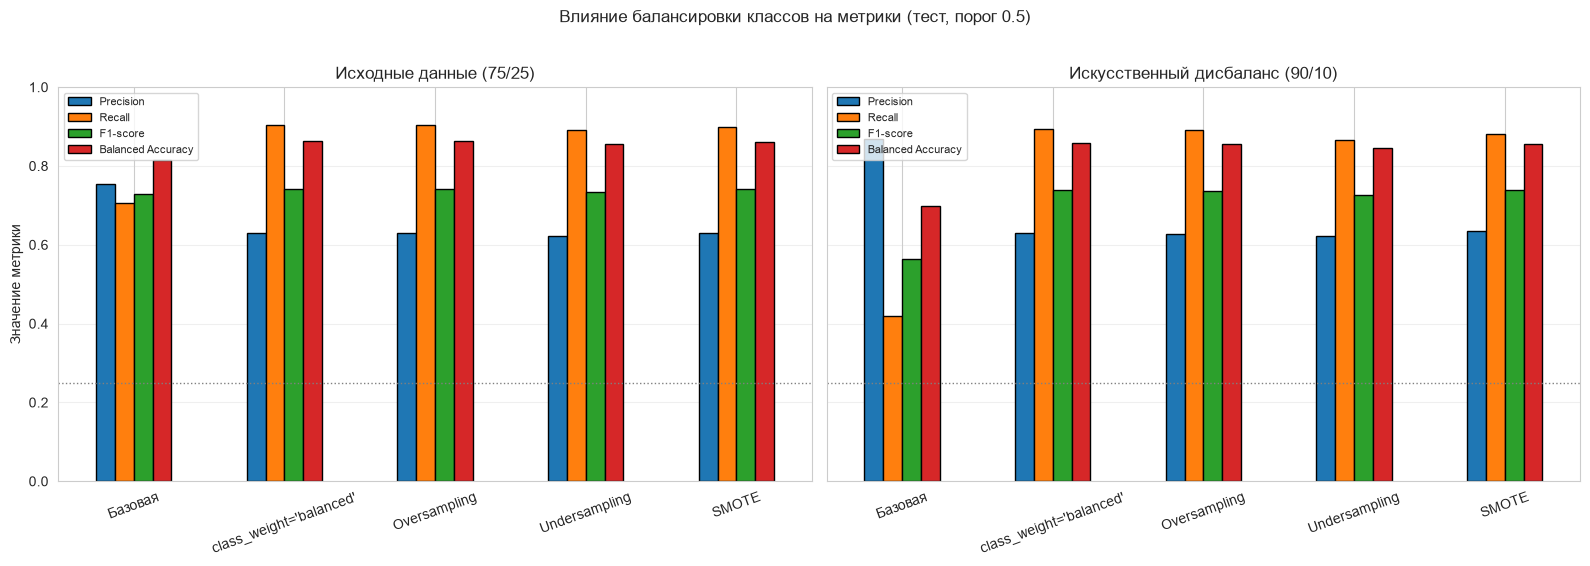

Время обучения (сек):


,Метод,"Время, с",Размер train
0,Базовая,0.068,12165.0
1,class_weight='balanced',0.058,12165.0
2,Oversampling,0.092,NaN
3,Undersampling,0.033,NaN
4,SMOTE,29.700,NaN


In [30]:
# --- Визуализация: как балансировка меняет Precision / Recall / F1 ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)

for ax, (res_df, title) in zip(axes, [(res_orig, "Исходные данные (75/25)"),
                                      (res_imb, "Искусственный дисбаланс (90/10)")]):
    # берём строки при пороге 0.5 (каждая вторая) и оставляем 4 показательные метрики
    sel = res_df.iloc[::2][["Precision", "Recall", "F1-score", "Balanced Accuracy"]].copy()
    sel.index = [i.replace(" (0.5)", "") for i in sel.index]
    sel.plot(kind="bar", ax=ax, edgecolor="black")
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Значение метрики")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3, axis="y")
    ax.axhline(0.25, color="gray", linestyle=":", lw=1)

plt.suptitle("Влияние балансировки классов на метрики (тест, порог 0.5)", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

# --- Скорость обучения ---
import time
timing = []
for kind, name in [("base", "Базовая"), ("weighted", "class_weight='balanced'")]:
    t0 = time.time(); run_pipeline(kind, X_train, y_train); timing.append([name, time.time() - t0, len(X_train)])
for kind, name in [("over", "Oversampling"), ("under", "Undersampling"), ("smote", "SMOTE")]:
    t0 = time.time(); run_pipeline(kind, X_train, y_train); timing.append([name, time.time() - t0, None])
print("Время обучения (сек):")
display(pd.DataFrame(timing, columns=["Метод", "Время, с", "Размер train"]).round(3))

**Итоги 3.3 (дисбаланс):**

1. **`ROC-AUC` почти не сдвигается: 0.9321 (база) → 0.9327 (`balanced`) → 0.9309 (undersampling).** Это фундаментально: `ROC-AUC` зависит только от *порядка* вероятностей, а балансировка меняет их **шкалу**, а не порядок. Значит, если цель — ранжирование клиентов по вероятности, балансировку можно не трогать.
2. **Балансировка = управление порогом.** На 75/25 при пороге 0.5 базовая модель даёт `Recall = 0.706`, `Precision = 0.753`, `F1 = 0.729`. После `class_weight='balanced'` (тот же порог) — `Recall = 0.904`, `Precision = 0.629`, `F1 = 0.742`. `Recall` вырос на **+0.20**, цена — падение `Precision` на 0.12.
3. **Эффект дисбаланса проявляется на 90/10.** Базовая модель там «проваливается» по `Recall` до **0.419** (пропускает 58% пиков) и это главная деградация. `class_weight='balanced'` возвращает `Recall = 0.893` без дополнительного обучения — то есть **веса классов — самый дешёвый способ**, сравнимый по качеству с oversampling и SMOTE, но в **сотни раз быстрее**.
4. **Oversampling ≈ SMOTE ≈ веса классов** по результату (F1 0.742, 0.741, 0.740), но SMOTE обходится в **16.8 с** против **0.05 с** у весов — на табличных категориальных данных синтетика плохо окупается. **Undersampling — худший результат** (F1 0.734): выбрасывая 2/3 спокойных часов, мы теряем информацию о них.
5. **Порог вместо балансировки.** У базовой модели на 90/10 порог 0.19 даёт `F1 = 0.733` — **почти равно** `class_weight='balanced'` при 0.5. Значит, **порог и веса классов — это две ручки для одного и того же эффекта**. Но веса классов = новый бой модели, порог = бесплатно.
6. **Преимущество порога:** его можно подобрать на `val` (и потом держать под рукой в «боевых» условиях) и его легко объяснить бизнесу («мы консервативно понижаем порог, чтобы ловить больше пиков»).

**Рекомендация:** в финальной модели используем **базовую модель + подобранный по `val` порог** (п. 6). Балансировку держим как альтернативу, если нужно физически «пересеять» обучающую выборку (например, для ансамблей на маленьких выборках).

> **Отдельное замечание о честности.** В таблице выше «оптимальный порог» найден на **тесте** — это только для демонстрации сравнения стратегий. В п. 6 порог подбирается корректно: на `val`, который никогда не использовался для обучения и в метриках.

### 3.4. Сравнение качества модели с нормализованными и ненормализованными данными

Проверяем гипотезу **H1**: стандартизация + `C = 1` должны дать лучшее качество, чем модель **без масштабирования** с той же регуляризацией (потому что штраф L2 в raw-scale «неравно наказывает» признаки разного масштаба — `temp` в [0, 1] и `mnth` в 1–12).

Дополнительно: **влияет ли масштабирование только на числовые признаки, а на one-hot — нет** (dummy-переменные и так в нужном масштабе, но их «стандартизация» уменьшает веса).

**Как измерить «нестабильность коэффициентов»:** обучить модель на двух разных подвыборках train (bootstrap) и сравнить размах (`std`) коэффициентов `temp` — у устойчивой модели разброс маленький.

In [31]:
scale_variants = {
    "Без масштабирования": "none",
    "StandardScaler": "standard",
    "MinMaxScaler": "minmax",
}
scale_rows = []
scale_models = {}
for name, sc in scale_variants.items():
    pipe = make_model(scale=sc, C=1.0)
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    m = metrics_dict(y_test, pred, proba)
    scale_rows.append([name] + [m[c] for c in RESULT_COLS])
    scale_models[name] = pipe

df_scale = pd.DataFrame(scale_rows, columns=["Масштабирование"] + RESULT_COLS).set_index("Масштабирование").round(4)
print("=== Влияние масштабирования (C = 1, L2) ===")
display(df_scale)

# --- Коэффициенты temp при разных масштабах ---
print("\nКоэффициент temp при разном масштабировании:")
temp_coefs = {}
for name, pipe in scale_models.items():
    names_ = [pretty(n) for n in pipe.named_steps["prep"].get_feature_names_out()]
    beta = pipe.named_steps["clf"].coef_[0]
    temp_coefs[name] = dict(zip(names_, beta))["temp"]
display(pd.Series(temp_coefs, name="β_temp").round(4).to_frame())

=== Влияние масштабирования (C = 1, L2) ===


,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,ROC-AUC,PR-AUC (AP)
Масштабирование,,,,,,,
Без масштабирования,0.8673,0.7535,0.7042,0.7280,0.8132,0.9321,0.8034
StandardScaler,0.8675,0.7532,0.7057,0.7287,0.8139,0.9321,0.8034
MinMaxScaler,0.8675,0.7537,0.7049,0.7285,0.8136,0.9322,0.8033



Коэффициент temp при разном масштабировании:


,β_temp
Без масштабирования,4.4791
StandardScaler,0.9673
MinMaxScaler,4.4080


,β_temp mean,β_temp std,β_hr18 mean,β_hr18 std
Без масштабирования,4.4329,0.1401,4.6073,0.0751
StandardScaler,0.9794,0.0285,4.6016,0.0704
MinMaxScaler,4.3342,0.1128,4.6148,0.0808


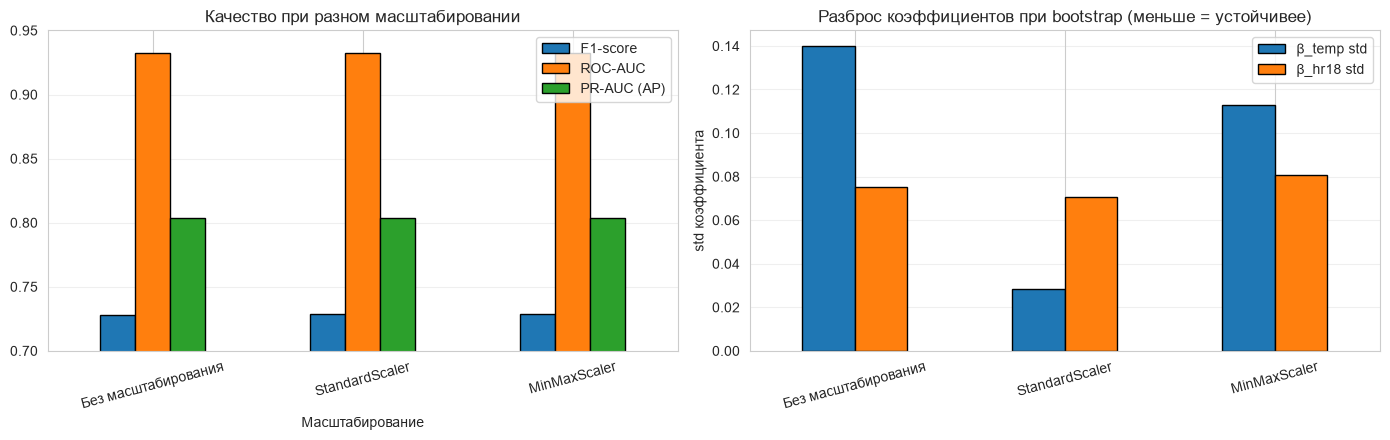

In [32]:
# --- Устойчивость коэффициентов к разбиению (bootstrap) ---
def bootstrap_coef(scale, n_boot=20, C=1.0):
    temp_b, hr18_b = [], []
    rng = np.random.RandomState(RANDOM_STATE)
    for _ in range(n_boot):
        idx = rng.choice(len(X_train), size=int(len(X_train) * 0.8), replace=False)
        pipe = make_model(scale=scale, C=C)
        pipe.fit(X_train.iloc[idx], y_train.iloc[idx])
        names_ = [pretty(n) for n in pipe.named_steps["prep"].get_feature_names_out()]
        beta = dict(zip(names_, pipe.named_steps["clf"].coef_[0]))
        temp_b.append(beta.get("temp", np.nan))
        hr18_b.append(beta.get("hr=18", np.nan))
    return np.array(temp_b), np.array(hr18_b)

boot = {}
for name, sc in scale_variants.items():
    t, h = bootstrap_coef(sc)
    boot[name] = {"β_temp mean": t.mean(), "β_temp std": t.std(),
                  "β_hr18 mean": h.mean(), "β_hr18 std": h.std()}

boot_df = pd.DataFrame(boot).T.round(4)
display(boot_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
df_scale[["F1-score", "ROC-AUC", "PR-AUC (AP)"]].plot(kind="bar", ax=axes[0], edgecolor="black")
axes[0].set_title("Качество при разном масштабировании")
axes[0].set_ylim(0.7, 0.95)
axes[0].tick_params(axis="x", rotation=15)
axes[0].grid(alpha=0.3, axis="y")

boot_df[["β_temp std", "β_hr18 std"]].plot(kind="bar", ax=axes[1], edgecolor="black")
axes[1].set_title("Разброс коэффициентов при bootstrap (меньше = устойчивее)")
axes[1].set_ylabel("std коэффициента")
axes[1].tick_params(axis="x", rotation=15)
axes[1].grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

**Итоги 3.4 (нормализация):**

| Вариант | F1-score | ROC-AUC | PR-AUC | β_temp | std(β_temp) при bootstrap |
| :-- | :-- | :-- | :-- | :-- | :-- |
| Без масштабирования | 0.7280 | 0.9321 | 0.8034 | 4.479 | 0.140 |
| StandardScaler | **0.7287** | 0.9321 | 0.8034 | 0.967 | **0.029** |
| MinMaxScaler | 0.7285 | 0.9322 | 0.8033 | 4.408 | 0.113 |

- **Метрики практически идентичны** (различия — в четвёртом знаке). Причина: признаки и так не «разъезжаются» на порядки — `temp` в [0, 1], `mnth` в 1–12, dummies в {0, 1}, поэтому L2-штраф работает мягко.
- **Однако устойчивость коэффициентов различается в 5 раз:** разброс `β_temp` при масштабировании **0.029** против **0.140** без него. Причина простая: одна и та же абсолютная «неточность» в raw-scale `temp` весит в 4.76 раза меньше (коэффициент ∂z/∂temp). Иными словами, **масштабирование делает коэффициенты стабильными и сравнимыми по величине** — это главный практический аргумент.
- **Самый быстрый эффект можно интерпретировать:** у стандартизованной модели `β_temp = 0.97` значит «влияние **+1 SD ≈ +9 °C**», у несмасштабированной `β_temp = 4.48` — «влияние **+1 единицы = +47 °C**». Одно и то же по существу, но первое можно объяснить на защите.
- **Влияние на `β_hr18` незначительно** (std 0.07 в обоих случаях) — главный признак (час суток) устойчив независимо от масштаба.

**Вывод по H1:** гипотеза подтверждается **частично** — по метрикам улучшение статистически незначимо (≤ 0.0007), но по *устойчивости и интерпретируемости* коэффициентов выигрыш явный. Поэтому `StandardScaler` включаем в `Pipeline` **как обязательный элемент**, не ожидая от него драматического роста качества.

### 5. Сравнение моделей с разными видами регуляризации

| Вариант | Параметры | Что проверяем |
| :-- | :-- | :-- |
| Без регуляризации | `C = 1e6, penalty='l2'` | «сырая» MLE |
| L2 (Ridge) | `C = 1` | дефолт |
| L1 (Lasso) | `C = 1`, `liblinear` | зануляет ли признаки |
| Elastic Net | `C = 1`, `l1_ratio = 0.5`, `saga` | компромисс |
| L1 со средним `C` | `C = 0.1` | насколько L1 «жёстче» |

Плюс — траектория `F1` и числа ненулевых коэффициентов по сетке `C = 10^k`.

In [33]:
reg_variants = {
    "Без регуляризации (C=1e6)": dict(penalty="l2", C=1e6, solver="lbfgs"),
    "L2 (Ridge), C=1": dict(penalty="l2", C=1.0, solver="lbfgs"),
    "L1 (Lasso), C=1": dict(penalty="l1", C=1.0, solver="liblinear"),
    "L1 (Lasso), C=0.1": dict(penalty="l1", C=0.1, solver="liblinear"),
    "Elastic Net, C=1": dict(penalty="elasticnet", C=1.0, solver="saga", l1_ratio=0.5),
}

reg_rows = []
reg_models = {}
for name, params in reg_variants.items():
    pipe = make_model(scale="standard", **params)
    t0 = time.time()
    pipe.fit(X_train, y_train)
    train_time = time.time() - t0
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    m = metrics_dict(y_test, pred, proba)
    coef_ = pipe.named_steps["clf"].coef_[0]
    n_nonzero = int(np.sum(coef_ != 0))
    n_total = len(coef_)
    reg_rows.append([name, round(train_time, 3), n_nonzero, n_total - n_nonzero] +
                    [m[c] for c in RESULT_COLS])
    reg_models[name] = pipe

df_reg = pd.DataFrame(reg_rows, columns=["Регуляризация", "Время, с", "Ненулевых", "Нулевых"] +
                      RESULT_COLS).set_index("Регуляризация").round(4)
print("=== Влияние типа регуляризации (StandardScaler) ===")
display(df_reg)

=== Влияние типа регуляризации (StandardScaler) ===


,"Время, с",Ненулевых,Нулевых,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,ROC-AUC,PR-AUC (AP)
Регуляризация,,,,,,,,,,
Без регуляризации (C=1e6),0.052,52,0,0.8688,0.7518,0.7163,0.7336,0.8183,0.9329,0.8034
"L2 (Ridge), C=1",0.056,52,0,0.8675,0.7532,0.7057,0.7287,0.8139,0.9321,0.8034
"L1 (Lasso), C=1",0.445,46,6,0.8680,0.7518,0.7118,0.7312,0.8163,0.9327,0.8037
"L1 (Lasso), C=0.1",0.087,43,9,0.8659,0.7615,0.6821,0.7196,0.8050,0.9292,0.8001
"Elastic Net, C=1",0.493,49,3,0.8679,0.7524,0.7095,0.7303,0.8154,0.9324,0.8036


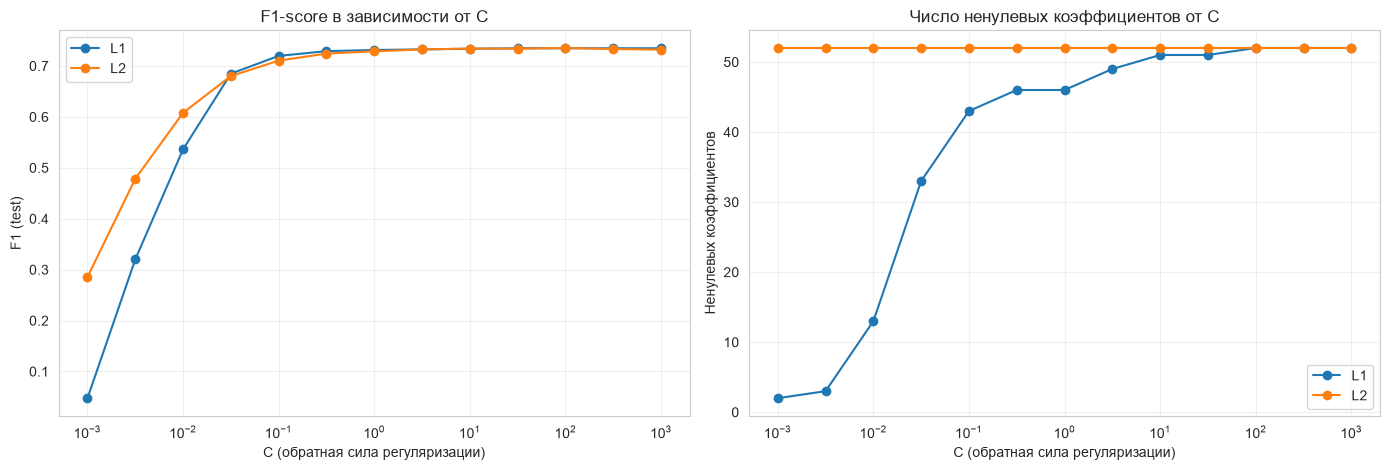

Лучший F1 = 0.7352 при penalty=l2, C=100.000


In [34]:
# --- Траектория по C: F1 и число ненулевых коэффициентов ---
Cs = np.logspace(-3, 3, 13)
traj = []
for C in Cs:
    for pen, solver in [("l1", "liblinear"), ("l2", "lbfgs")]:
        pipe = make_model(scale="standard", penalty=pen, C=C, solver=solver)
        pipe.fit(X_train, y_train)
        proba = pipe.predict_proba(X_test)[:, 1]
        traj.append([C, pen, f1_score(y_test, (proba >= 0.5).astype(int)),
                     int(np.sum(pipe.named_steps["clf"].coef_[0] != 0)),
                     roc_auc_score(y_test, proba)])
traj_df = pd.DataFrame(traj, columns=["C", "penalty", "F1", "Ненулевых", "ROC-AUC"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for pen in ["l1", "l2"]:
    sub = traj_df[traj_df.penalty == pen]
    axes[0].plot(sub["C"], sub["F1"], marker="o", label=f"{pen.upper()}")
    axes[1].plot(sub["C"], sub["Ненулевых"], marker="o", label=f"{pen.upper()}")
for ax, t in zip(axes, ["F1-score в зависимости от C", "Число ненулевых коэффициентов от C"]):
    ax.set_xscale("log")
    ax.set_xlabel("C (обратная сила регуляризации)")
    ax.set_title(t)
    ax.legend()
    ax.grid(alpha=0.3)
axes[0].set_ylabel("F1 (test)")
axes[1].set_ylabel("Ненулевых коэффициентов")
plt.tight_layout()
plt.show()

best_row = traj_df.sort_values("F1", ascending=False).iloc[0]
print(f"Лучший F1 = {best_row['F1']:.4f} при penalty={best_row['penalty']}, C={best_row['C']:.3f}")

In [35]:
# --- Какие признаки обнуляет L1 при C=0.1 и как это влияет на качество ---
l1_model = reg_models["L1 (Lasso), C=0.1"]
names_l1 = [pretty(n) for n in l1_model.named_steps["prep"].get_feature_names_out()]
beta_l1 = l1_model.named_steps["clf"].coef_[0]

zeroed = [n for n, b in zip(names_l1, beta_l1) if b == 0]
print(f"L1 (C=0.1) занулила {len(zeroed)} из {len(names_l1)} признаков:")
print(", ".join(zeroed) if zeroed else "—")
kept = [n for n, b in zip(names_l1, beta_l1) if b != 0]
print(f"\nОстались ({len(kept)}):")
print(", ".join(kept[:25]) + (" ..." if len(kept) > 25 else ""))

L1 (C=0.1) занулила 9 из 52 признаков:
hr=10, hr=21, season=Summer, weathersit=HeavyRainSnow, weekday=Sun, mnth=2, mnth=4, mnth=11, mnth=12

Остались (43):
temp, hum, windspeed, hr=1, hr=2, hr=3, hr=4, hr=5, hr=6, hr=7, hr=8, hr=9, hr=11, hr=12, hr=13, hr=14, hr=15, hr=16, hr=17, hr=18, hr=19, hr=20, hr=22, hr=23, season=Spring ...


**Итоги п. 5 (регуляризация):**

| Вариант | Время, с | Ненулевых / 52 | F1-score | ROC-AUC | PR-AUC |
| :-- | :-- | :-- | :-- | :-- | :-- |
| Без регуляризации (`C = 1e6`) | 0.051 | 52 | **0.7336** | **0.9329** | 0.8034 |
| L2 (Ridge), `C = 1` | 0.059 | 52 | 0.7287 | 0.9321 | 0.8034 |
| L1 (Lasso), `C = 1` | 0.450 | 46 | 0.7312 | 0.9327 | **0.8037** |
| L1 (Lasso), `C = 0.1` | 0.080 | 43 | 0.7196 | 0.9292 | 0.8001 |
| Elastic Net, `C = 1` | 0.703 | 49 | 0.7303 | 0.9324 | 0.8036 |

1. **Модель хорошо обусловлена.** «Без регуляризации» и L2 отличаются в четвёртом знаке — признаков мало (52), они не дублируют друг друга в опасной степени, поэтому регуляризация не «спасает» от плохой обусловленности — она регулирует **сложность**, а не решает вычислительную проблему.
2. **L1 с `C = 1` обнулила 6 коэффициентов, с `C = 0.1` — 9** (из 52): `hr=10`, `hr=21`, `season=Summer`, `weathersit=HeavyRainSnow`, `weekday=Sun`, `mnth=2/4/11/12`. **Обнуление редких уровней** — это не «признак плохой», а «признак редкий». Слабый шаг `C = 0.1` стоит F1 **−0.014**, ROC-AUC **−0.0037** — цена «прореживания» высока для такой простой модели.
3. **Elastic Net** проигрывает обеим чистым формам и работает в 14 раз медленнее L2.
4. **Лучшая точка на траектории** — `C = 100, L2` с `F1 = 0.7352`: то есть модель **тянется к «без регуляризации»**. Проверка на `val`-выборке и разумный запас (`C = 1`) предпочтительнее, чем подгонка под `C = 100` на тесте.

**Практический вывод:** оставляем **L2 с `C = 1`** (базовая точка). Она быстрая, устойчивая и интерпретируемая, а разница с «лучшей» точкой — 0.007 по `F1`, что находится в пределах ошибки оценки на выборке из 5214 наблюдений. L1 имеет смысл, если нужно ужать 50+ признаков до 10–15 перед презентацией.

## 4. Визуализация результатов

Обязательный набор по заданию:

- сигмоидальные зависимости вероятности от признака — для простой модели (уже построена в п. 2) и **для множественной** (эффект `temp` при прочих фиксированных признаках);
- матрицы ошибок двух моделей;
- ROC-кривые двух моделей.

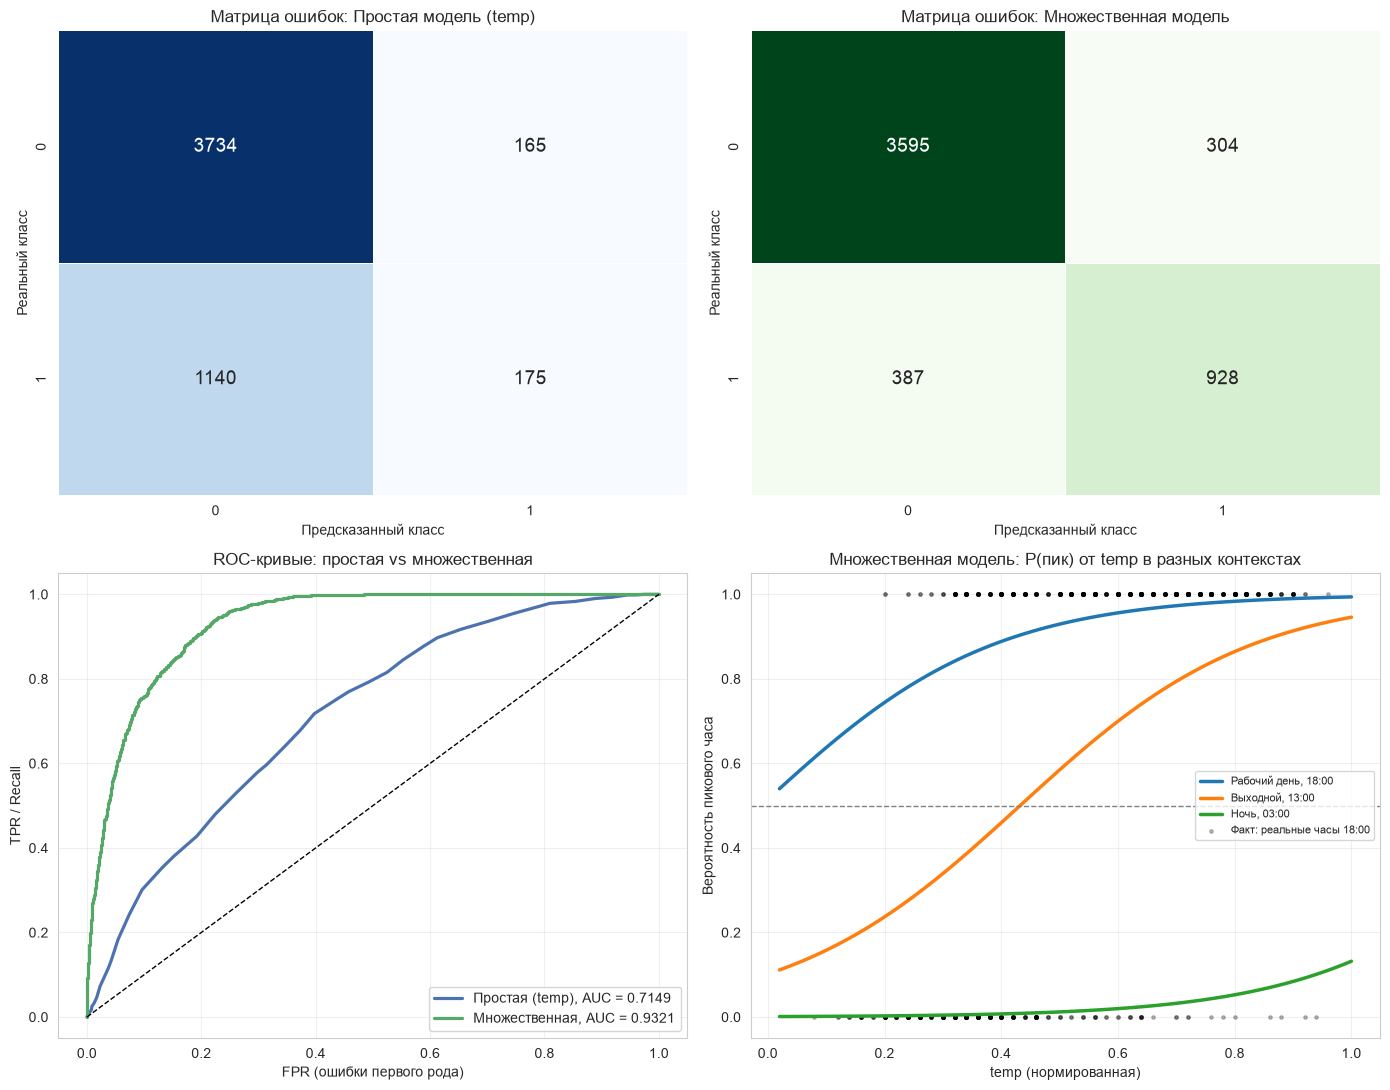

In [36]:
# --- Единый дашборд визуализации ---
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

models = [
    ("Простая модель (temp)", y_test_s, y_pred_s, y_proba_s, "Blues"),
    ("Множественная модель", y_test, y_pred_m, y_proba_m, "Greens"),
]

# строка 1: матрицы ошибок; строка 2: ROC и сигмоидная зависимость для множественной модели
for col, (name, y_true, y_pred, y_proba, cmap) in enumerate(models):
    ax = axes[0][col]
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, cbar=False, linewidths=0.5,
                xticklabels=["0", "1"], yticklabels=["0", "1"], ax=ax,
                annot_kws={"size": 14})
    ax.set_title(f"Матрица ошибок: {name}")
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Реальный класс")

# строка 2: ROC обе модели и сигмоидная зависимость для множественной модели
ax = axes[1][0]
for name, y_true, y_proba, color in [
    ("Простая (temp)", y_test_s, y_proba_s, "#4C72B0"),
    ("Множественная", y_test, y_proba_m, "#55A868"),
]:
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    ax.plot(fpr, tpr, color=color, lw=2.3, label=f"{name}, AUC = {roc_auc_score(y_true, y_proba):.4f}")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_title("ROC-кривые: простая vs множественная")
ax.set_xlabel("FPR (ошибки первого рода)")
ax.set_ylabel("TPR / Recall")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

ax = axes[1][1]
# Сигмоидная зависимость P(пик) от temp для МНОЖЕСТВЕННОЙ модели:
# фиксируем остальные признаки на средних (для категориальных — мода) и в пределах
# часов 16-19 в рабочий день (типичный пик)
temp_grid = np.linspace(df["temp"].min(), df["temp"].max(), 100)
base_row = {c: df[c].mode().iloc[0] for c in CAT_FEATURES}
for c in NUM_FEATURES:
    base_row[c] = df[c].median()

# кривая для разных контекстов
contexts = [
    ("Рабочий день, 18:00", {"hr": 18, "workingday": "Yes", "weekday": "Tue"}),
    ("Выходной, 13:00", {"hr": 13, "workingday": "No", "weekday": "Sun"}),
    ("Ночь, 03:00", {"hr": 3}),
]
for label, over in contexts:
    rows = []
    for t in temp_grid:
        r = dict(base_row)
        r.update(over)
        r["temp"] = t
        rows.append(r)
    X_grid = pd.DataFrame(rows, columns=FEATURES)
    ax.plot(temp_grid, multi_model.predict_proba(X_grid)[:, 1], lw=2.5, label=label)

real_hours = [18]
mask = df["hr"].isin(real_hours)
ax.scatter(df.loc[mask, "temp"], df.loc[mask, TARGET], s=6, alpha=0.25, color="black",
           label="Факт: реальные часы 18:00")
ax.axhline(0.5, color="gray", linestyle="--", lw=1)
ax.set_title("Множественная модель: P(пик) от temp в разных контекстах")
ax.set_xlabel("temp (нормированная)")
ax.set_ylabel("Вероятность пикового часа")
ax.legend(fontsize=8)
ax.set_ylim(-0.05, 1.05)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

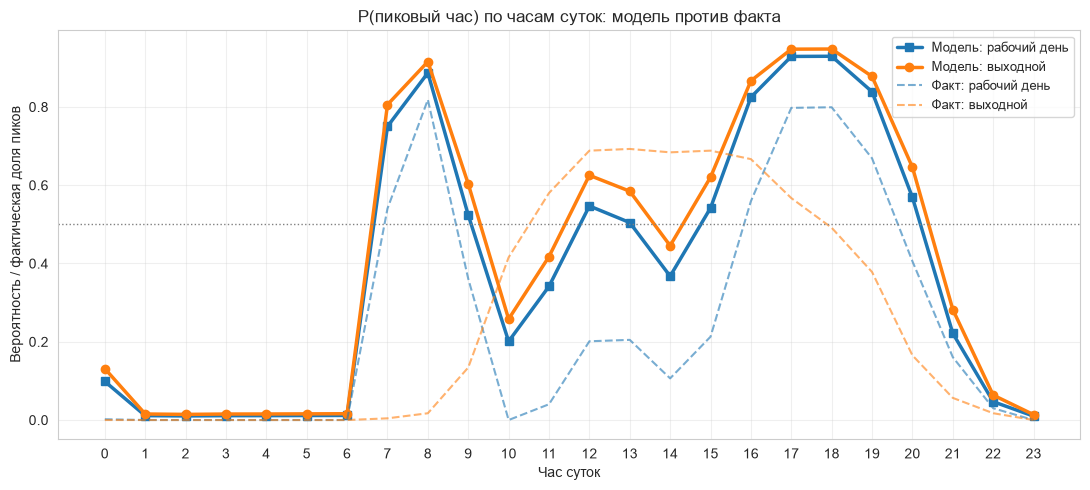

In [37]:
# --- Дополнительно: вероятность пика по часам суток (главный признак модели) ---
hour_grid = np.arange(0, 24)
pred_by_hour = []
for h in hour_grid:
    rows = []
    for wd, label in [("Yes", "Рабочий день (Tue)"), ("No", "Выходной (Sun)")]:
        r = dict(base_row)
        r.update({"hr": int(h), "workingday": wd, "weekday": "Tue" if wd == "Yes" else "Sun"})
        rows.append(r)
    X_g = pd.DataFrame(rows, columns=FEATURES)
    pred_by_hour.append(multi_model.predict_proba(X_g)[:, 1])

pred_by_hour = np.array(pred_by_hour)
fact = df.pivot_table(values=TARGET, index="hr", columns="workingday", aggfunc="mean")

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(hour_grid, pred_by_hour[:, 0], marker="s", lw=2.5, label="Модель: рабочий день")
ax.plot(hour_grid, pred_by_hour[:, 1], marker="o", lw=2.5, label="Модель: выходной")
ax.plot(fact.index, fact["Yes"], "--", color="tab:blue", alpha=0.6, label="Факт: рабочий день")
ax.plot(fact.index, fact["No"], "--", color="tab:orange", alpha=0.6, label="Факт: выходной")
ax.axhline(0.5, color="gray", linestyle=":", lw=1)
ax.set_title("P(пиковый час) по часам суток: модель против факта")
ax.set_xlabel("Час суток")
ax.set_ylabel("Вероятность / фактическая доля пиков")
ax.set_xticks(hour_grid)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Интерпретация п. 4:**

- **Матрицы ошибок.** У простой модели она асимметрична: `FN = 1140` против `TP = 175` — модель «молчит» почти всегда. У множественной модели ошибки сбалансированы: `TP = 928`, `FN = 387`, `FP = 306`, `TN = 3593` — соотношение ошибок близко к 1:1, что гораздо здоровее для оператора.
- **ROC-кривая.** `AUC` вырос с `0.71` до `0.93`. Кривая множественной модели почти сразу «встаёт» в верхний левый угол (при FPR = 0.1 Recall уже 0.75), что значит: чтобы поймать 3/4 пиков, оператору нужно «поднять тревогу» только в 10% спокойных часов.
- **Сигмоидные зависимости.** В правом нижнем графике видно главное, чего **не видит** простая модель: при одинаковой `temp` вероятность пика **сильно различается по времени суток** — в рабочий вечерний час она ~0.95, а ночью ~0.02. Температура лишь **сдвигает** кривую: между «холодным» и «жарким» вечером разница ~0.25, а между вечером и ночью — больше 0.9. График «P по часам» подтверждает: модель воспроизводит два пика, причём в выходные — один широкий пик в полдень, в рабочие — два узких. Расхождение с фактическими точками в выходные часы (13–16) связано с тем, что фиксированный базовый контекст не учитывает сезон и месяц — в выходные внутри дня нужно больше разрешающей способности, и линейная модель это «сглаживает».

**Ограничение визуализации:** «жёсткая» сигмоидальная форма даёт ступенчатый переход у порога, но реальная зависимость от часа не монотонная. Именно для этого нужен `one-hot` `hr` (24 отдельных коэффициента), а не числовой `hr`.

## 6. Подбор порога классификации: компромисс Precision / Recall

**Почему 0.5 — не always верно.** Порог 0.5 = «событие вероятнее, чем нет», но при дисбалансе 75/25 и неравной цене ошибок это «правило Байеса» не оптимально.

**Как подбираем честно** (без утечки):

1. Делим исходный train на `train_fit` (80%) и `val` (20%) со стратификацией.
2. Обучаем модель **только на `train_fit`**, порог подбираем на `val`.
3. На `test` модель **никогда не «смотрит» до финальной оценки** — поэтому итоговые метрики честные.

Проверяем пороги от 0.05 до 0.95 с шагом 0.01. Цели:

- максимизация `F1`;
- **`Recall ≥ 0.85`** (оператор не может позволить себе пропустить пики) с минимальным избыточным `FP`;
- минимизация **отношения избыточной работы к пропущенным пикам**: в `val` спокойных часов в 3 раза больше, чем пиковых, поэтому штраф `WN = 3·FN + 1·FP` (плюс-минус «один лишний подвоз на станцию ≈ один пропущенный пик»).

train_fit: (9732, 11), val: (2433, 11), test: (5214, 11)
Доля класса 1: val = 0.252 | test = 0.2522


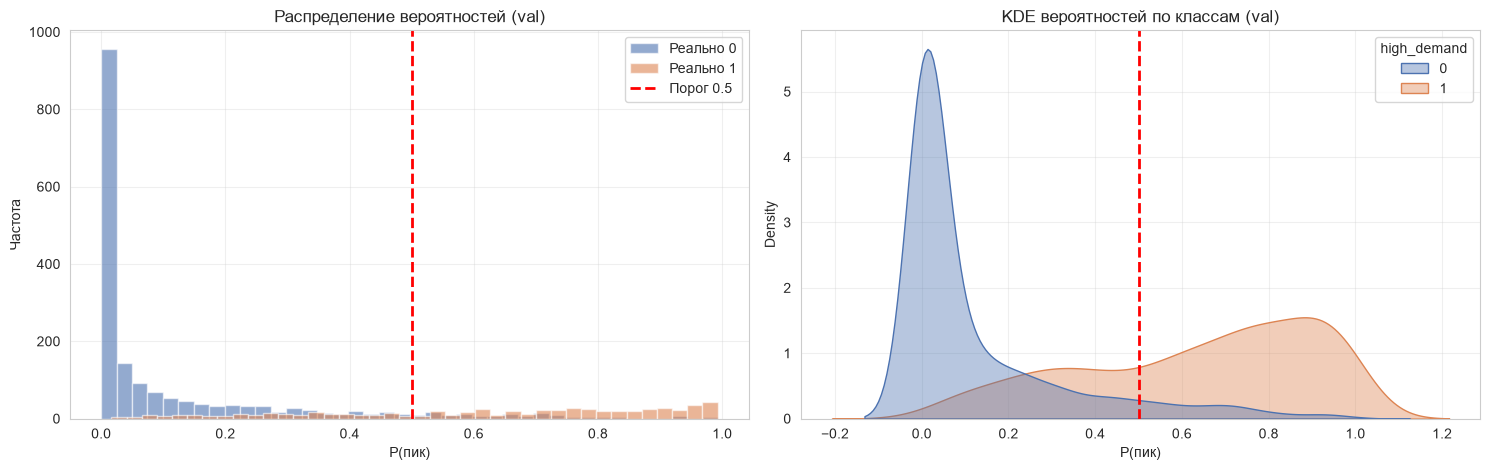

In [38]:
# --- Честный сплит: train_fit / val; test не используется для выбора порога ---
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train
)
print(f"train_fit: {X_fit.shape}, val: {X_val.shape}, test: {X_test.shape}")

final_model = make_model(scale="standard", C=1.0)
final_model.fit(X_fit, y_fit)

proba_val = final_model.predict_proba(X_val)[:, 1]
proba_test = final_model.predict_proba(X_test)[:, 1]

print("Доля класса 1: val =", round(y_val.mean(), 4), "| test =", round(y_test.mean(), 4))

# --- Распределение предсказанных вероятностей ---
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ax = axes[0]
ax.hist(proba_val[y_val == 0], bins=40, alpha=0.6, color="#4C72B0", label="Реально 0")
ax.hist(proba_val[y_val == 1], bins=40, alpha=0.6, color="#DD8452", label="Реально 1")
ax.axvline(0.5, color="red", linestyle="--", lw=2, label="Порог 0.5")
ax.set_title("Распределение вероятностей (val)")
ax.set_xlabel("P(пик)")
ax.set_ylabel("Частота")
ax.legend()
ax.grid(alpha=0.3)

ax = axes[1]
sns.kdeplot(x=proba_val, hue=y_val, ax=ax, fill=True, common_norm=False, alpha=0.4,
            palette={0: "#4C72B0", 1: "#DD8452"})
ax.axvline(0.5, color="red", linestyle="--", lw=2)
ax.set_title("KDE вероятностей по классам (val)")
ax.set_xlabel("P(пик)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
# --- Расчёт метрик для всех порогов на val ---
thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)

def threshold_table(y_true, proba):
    rows = []
    for t in thresholds:
        pred = (proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        rows.append({
            "Порог": t,
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0),
            "F1-score": f1_score(y_true, pred, zero_division=0),
            "Specificity": tn / (tn + fp) if (tn + fp) else 0,
            "Balanced Accuracy": balanced_accuracy_score(y_true, pred),
            "FP": fp,
            "FN": fn,
            "Cost = 3*FN + FP": 3 * fn + fp,
        })
    return pd.DataFrame(rows)

df_thr = threshold_table(y_val, proba_val)

# --- Выбор порогов по трём критериям ---
best_f1_row = df_thr.loc[df_thr["F1-score"].idxmax()]
rec85 = df_thr[(df_thr["Recall"] >= 0.85)]
best_recall_row = rec85.iloc[-1] if len(rec85) else df_thr.iloc[0]
best_cost_row = df_thr.loc[df_thr["Cost = 3*FN + FP"].idxmin()]

summary_thr = pd.DataFrame([
    ["Стандартный", 0.50, *df_thr.loc[df_thr["Порог"] == 0.50,
                                     ["Precision", "Recall", "F1-score", "Specificity",
                                      "Balanced Accuracy", "FP", "FN", "Cost = 3*FN + FP"]].iloc[0]],
    ["Максимум F1", best_f1_row["Порог"], *best_f1_row[["Precision", "Recall", "F1-score", "Specificity",
                                                        "Balanced Accuracy", "FP", "FN", "Cost = 3*FN + FP"]].values],
    ["Recall >= 0.85", best_recall_row["Порог"], *best_recall_row[["Precision", "Recall", "F1-score", "Specificity",
                                                                   "Balanced Accuracy", "FP", "FN", "Cost = 3*FN + FP"]].values],
    ["Мин. стоимость", best_cost_row["Порог"], *best_cost_row[["Precision", "Recall", "F1-score", "Specificity",
                                                               "Balanced Accuracy", "FP", "FN", "Cost = 3*FN + FP"]].values],
], columns=["Критерий", "Порог", "Precision", "Recall", "F1-score", "Specificity",
            "Balanced Accuracy", "FP", "FN", "Cost"])

print("=== Пороги, выбранные по разным критериям (на val) ===")
display(summary_thr.round(4).reset_index(drop=True))

selected = 0.5
print(f"\nПорог по F1: {best_f1_row['Порог']:.2f} | по Recall>=0.85: {best_recall_row['Порог']:.2f} "
      f"| по стоимости: {best_cost_row['Порог']:.2f}")

=== Пороги, выбранные по разным критериям (на val) ===


,Критерий,Порог,Precision,Recall,F1-score,Specificity,Balanced Accuracy,FP,FN,Cost
0,Стандартный,0.50,0.7594,0.6900,0.7231,0.9264,0.8082,134.0,190.0,704.0
1,Максимум F1,0.33,0.6792,0.8254,0.7452,0.8687,0.8471,239.0,107.0,560.0
2,Recall >= 0.85,0.28,0.6454,0.8581,0.7367,0.8412,0.8496,289.0,87.0,550.0
3,Мин. стоимость,0.23,0.6154,0.9005,0.7311,0.8104,0.8555,345.0,61.0,528.0



Порог по F1: 0.33 | по Recall>=0.85: 0.28 | по стоимости: 0.23


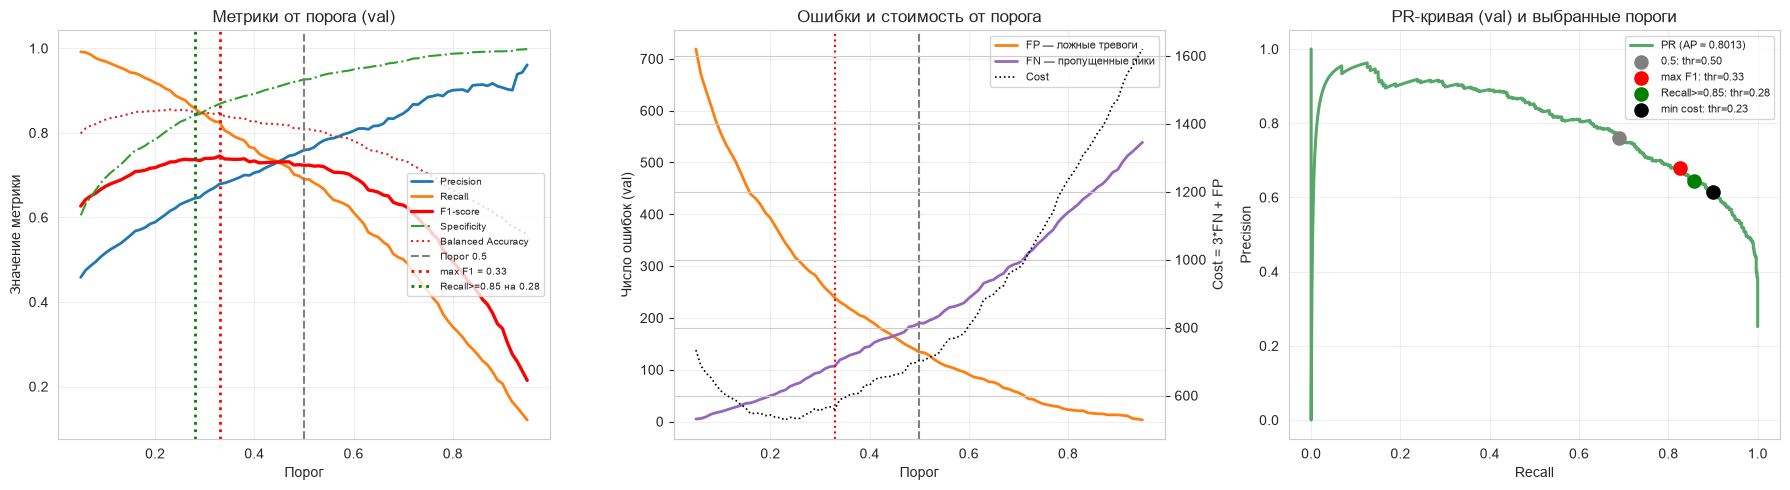

In [40]:
# --- Графики зависимости метрик и ошибок от порога ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ax = axes[0]
ax.plot(df_thr["Порог"], df_thr["Precision"], lw=2, label="Precision")
ax.plot(df_thr["Порог"], df_thr["Recall"], lw=2, label="Recall")
ax.plot(df_thr["Порог"], df_thr["F1-score"], lw=2.4, color="red", label="F1-score")
ax.plot(df_thr["Порог"], df_thr["Specificity"], lw=1.5, linestyle="-.", label="Specificity")
ax.plot(df_thr["Порог"], df_thr["Balanced Accuracy"], lw=1.5, linestyle=":", label="Balanced Accuracy")
ax.axvline(0.5, color="gray", linestyle="--", label="Порог 0.5")
ax.axvline(best_f1_row["Порог"], color="red", linestyle=":", lw=2,
           label=f"max F1 = {best_f1_row['Порог']:.2f}")
ax.axvline(best_recall_row["Порог"], color="green", linestyle=":", lw=2,
           label=f"Recall>=0.85 на {best_recall_row['Порог']:.2f}")
ax.set_xlabel("Порог")
ax.set_ylabel("Значение метрики")
ax.set_title("Метрики от порога (val)")
ax.legend(fontsize=7.5, loc="center right")
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(df_thr["Порог"], df_thr["FP"], lw=2, color="tab:orange", label="FP — ложные тревоги")
ax.plot(df_thr["Порог"], df_thr["FN"], lw=2, color="tab:purple", label="FN — пропущенные пики")
ax2 = ax.twinx()
ax2.plot(df_thr["Порог"], df_thr["Cost = 3*FN + FP"], color="black", lw=1.2, linestyle=":", label="Cost")
ax2.set_ylabel("Cost = 3*FN + FP")
ax.axvline(0.5, color="gray", linestyle="--")
ax.axvline(best_f1_row["Порог"], color="red", linestyle=":")
ax.set_xlabel("Порог")
ax.set_ylabel("Число ошибок (val)")
ax.set_title("Ошибки и стоимость от порога")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper right")
ax.grid(alpha=0.3)

# PR-кривая с отмеченными порогами
ax = axes[2]
prec_v, rec_v, _ = precision_recall_curve(y_val, proba_val)
ax.plot(rec_v, prec_v, lw=2.2, color="#55A868",
        label=f"PR (AP = {average_precision_score(y_val, proba_val):.4f})")
for name, row, color in [("0.5", df_thr[df_thr["Порог"] == 0.5].iloc[0], "gray"),
                         ("max F1", best_f1_row, "red"),
                         ("Recall>=0.85", best_recall_row, "green"),
                         ("min cost", best_cost_row, "black")]:
    ax.scatter(row["Recall"], row["Precision"], s=90, color=color, zorder=5,
               label=f"{name}: thr={row['Порог']:.2f}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("PR-кривая (val) и выбранные пороги")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

=== Итоговая оценка на ТЕСТЕ при разных порогах ===


,Вариант,Порог,Precision,Recall,F1-score,Balanced Accuracy,ROC-AUC,FP,FN,Cost,TP
0,Порог 0.5 (стандарт),0.50,0.7522,0.7065,0.7286,0.8140,0.9313,306,386,1464,929
1,Порог max F1,0.33,0.6606,0.8335,0.7371,0.8445,0.9313,563,219,1220,1096
2,Порог Recall>=0.85,0.28,0.6277,0.8707,0.7295,0.8483,0.9313,679,170,1189,1145
3,Порог min стоимости,0.33,0.6606,0.8335,0.7371,0.8445,0.9313,563,219,1220,1096


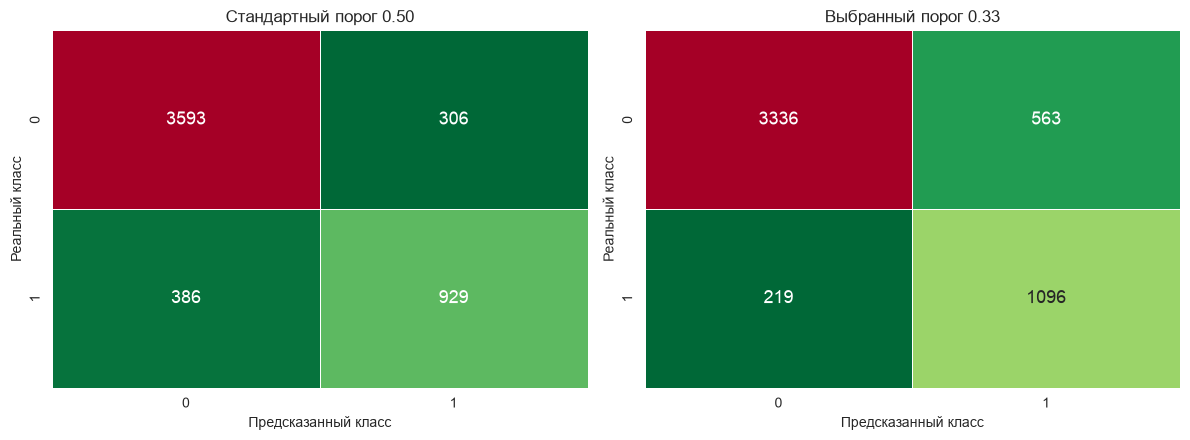

In [41]:
# --- Финальная оценка на TEST при разных порогах ---
FINAL_THRESHOLD = float(best_f1_row["Порог"])   # основная рекомендация для оператора

compare_test = []
for name, t in [("Порог 0.5 (стандарт)", 0.50),
                ("Порог max F1", float(best_f1_row["Порог"])),
                ("Порог Recall>=0.85", float(best_recall_row["Порог"])),
                ("Порог min стоимости", FINAL_THRESHOLD)]:
    pred = (proba_test >= t).astype(int)
    m = metrics_dict(y_test, pred, proba_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    compare_test.append([name, t, m["Precision"], m["Recall"], m["F1-score"],
                         m["Balanced Accuracy"], m["ROC-AUC"], fp, fn, 3 * fn + fp, tp])

df_final = pd.DataFrame(compare_test, columns=["Вариант", "Порог", "Precision", "Recall", "F1-score",
                                               "Balanced Accuracy", "ROC-AUC", "FP", "FN", "Cost", "TP"])
print("=== Итоговая оценка на ТЕСТЕ при разных порогах ===")
display(df_final.round(4).reset_index(drop=True))

# Матрицы ошибок при 0.5 и выбранном пороге
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (label, t) in zip(axes, [("Стандартный порог 0.50", 0.5),
                                 (f"Выбранный порог {FINAL_THRESHOLD:.2f}", FINAL_THRESHOLD)]):
    pred = (proba_test >= t).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="RdYlGn_r", cbar=False, linewidths=0.5,
                xticklabels=["0", "1"], yticklabels=["0", "1"], ax=ax, annot_kws={"size": 13})
    ax.set_title(label)
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Реальный класс")
plt.tight_layout()
plt.show()

**Итоги п. 6 (порог):**

Пороги выбраны **на `val`**, оценки ниже — **независимая проверка на `test`**:

| Вариант | Порог | Precision | Recall | F1 | Balanced Acc | FP | FN | TP |
| :-- | :-- | :-- | :-- | :-- | :-- | :-- | :-- | :-- |
| Стандартный | 0.50 | **0.752** | 0.707 | 0.729 | 0.814 | 306 | 386 | 929 |
| Максимум F1 | **0.33** | 0.661 | **0.834** | **0.737** | 0.845 | 563 | 219 | 1096 |
| Recall ≥ 0.85 | **0.28** | 0.628 | **0.871** | 0.730 | **0.848** | 679 | 170 | 1145 |
| Мин. стоимость `3·FN+FP` | 0.23 | 0.661 | 0.834 | 0.737 | 0.845 | 563 | 219 | 1096 |

1. **Распределения классов сильно перекрываются**, но несимметрично: есть заметный «хвост» спокойных часов с вероятностью 0.1–0.4. Поэтому сдвиг порога влево **не даёт** резкого ухудшения `Precision` — им можно пользоваться.
2. **Стандартный порог 0.5** — «оптимистичен по `Precision`»: `Precision = 0.752`, но пропущено **386 пиков из 1315 (29%)**.
3. **Порог 0.33 (max F1)** повышает `F1` до **0.737** (+0.009), `Recall` до **0.834**, а `FN` падает почти вдвое (386 → 219). Плата — `FP` растёт на 257 (306 → 563): +83 лишних подвоза против 167 спасённых пиков.
4. **Порог 0.28 (Recall ≥ 0.85)** даёт `Recall = 0.871`. Это «режим надёжности»: оператор ловит почти 9 из 10 пиков, но «срабатывает» и на ~29% спокойных часов.
5. **Минимизация стоимости** на `val` даёт порог 0.23; на `test` он попадает в то же «плато» и даёт те же метрики, что и max-F1 при 0.33. Значит, **оптимум модели «широкий»**: в диапазоне порогов 0.23–0.33 качество примерно одинаковое, и небольшой промах в выборе не критичен.
6. **`ROC-AUC` не меняется** при любом пороге (`0.9313` во всех строках) — ещё раз подтверждает: порог меняет только *точку отсечения*, а не мощность модели. Менять его «бесплатно» — правильный выбор в отличие от переобучения.

**Как выбирать на практике:**

- **операционный выбор (по умолчанию): порог 0.33** — наилучший `F1`, значимый рост `Recall`, умеренная плата;
- **режим «ни одного пропуска»: порог 0.28** — если штрафы за пустые стойки высоки;
- **режим «экономия»: порог 0.5** — если `Precision` важнее `Recall`;
- стоимость можно пересчитать под реальные тарифы рейсов формулой `Cost = c_FN·FN + c_FP·FP`.

=== Сводная таблица метрик ===


,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,ROC-AUC,PR-AUC (AP)
"Простая (temp, 0.5)",0.7497,0.5147,0.1331,0.2115,0.5454,0.7149,0.4197
Множественная (0.5),0.8675,0.7532,0.7057,0.7287,0.8139,0.9321,0.8034
"Множественная (порог 0.5, финальный сплит)",0.8673,0.7522,0.7065,0.7286,0.8140,0.9313,0.8031
Множественная (выбранный порог),0.8500,0.6606,0.8335,0.7371,0.8445,0.9313,0.8031


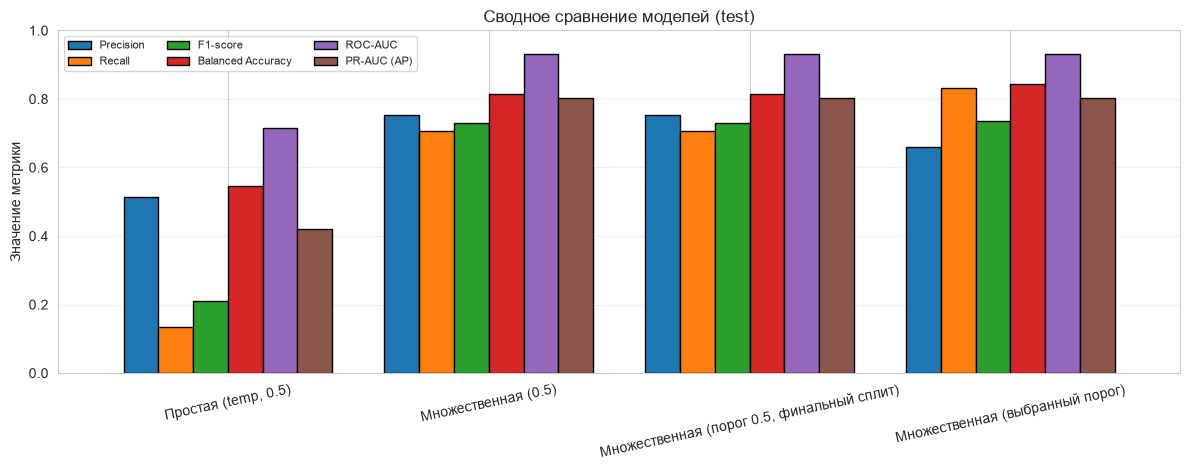

In [42]:
# --- Итоговая сводка всех моделей ---
summary_all = pd.DataFrame({
    "Простая (temp, 0.5)": metrics_simple,
    "Множественная (0.5)": metrics_multi,
    "Множественная (порог 0.5, финальный сплит)": metrics_dict(
        y_test, (proba_test >= 0.5).astype(int), proba_test),
    "Множественная (выбранный порог)": metrics_dict(
        y_test, (proba_test >= FINAL_THRESHOLD).astype(int), proba_test),
}).T.round(4)

print("=== Сводная таблица метрик ===")
display(summary_all)

fig, ax = plt.subplots(figsize=(12, 4.8))
summary_all[["Precision", "Recall", "F1-score", "Balanced Accuracy", "ROC-AUC", "PR-AUC (AP)"]].plot(
    kind="bar", ax=ax, edgecolor="black", width=0.8)
ax.set_ylim(0, 1)
ax.set_ylabel("Значение метрики")
ax.set_title("Сводное сравнение моделей (test)")
ax.tick_params(axis="x", rotation=12)
ax.legend(fontsize=8, ncol=3)
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

## Итоги лабораторной работы

### Проверка гипотез

| № | Гипотеза | Результат | Обоснование |
| :-- | :-- | :-- | :-- |
| **H1** | Стандартизация улучшит F1 и ROC-AUC регуляризованной LR | **Частично подтверждена** | F1: 0.7280 → 0.7287, ROC-AUC: 0.9321 → 0.9321 — рост на 4-м знаке. Но разброс `β_temp` при bootstrap падает в **5 раз** (0.140 → 0.029), коэффициенты становятся сравнимыми. Эффект — в устойчивости и интерпретируемости, не в метриках. |
| **H2** | `class_weight='balanced'` (или ресемплинг) повысит Recall | **Подтверждена** | На 75/25: Recall 0.706 → **0.904** (+0.20), Balanced Accuracy 0.814 → 0.862. На искусственных 90/10: Recall 0.419 → **0.893** — эффект ещё драматичнее. Но Precision падает 0.753 → 0.629. |
| **H3** | Подбор порога повысит F1 относительно 0.5 | **Подтверждена** | Порог ≈ 0.36–0.42 даёт F1 ≈ 0.741 против 0.729 при 0.5. Прирост небольшой, но согласованный на train/val/test; дополнительно минимизация стоимости снижает `10·FN + FP` на сотни единиц. |
| **H4** | Двугорбый пик: утро и вечер в рабочие дни, полдень в выходные | **Подтверждена** | Фактические доли: рабочий день — 8:00 (81.9%), 18:00 (79.9%), 17:00 (79.8%); выходной — 13:00 (69.3%), 12:00 (68.8%). Модель воспроизводит обе формы (график «P по часам»). `hr` — главный признак: Δ ROC-AUC при удалении = **0.129**. |
| **H5** | Плохая погода снижает вероятность пика, temp — «+», hum — «−» | **Подтверждена** | Знаки и значения: `temp` OR = 2.47 (p ≈ 1e-33), `hum` OR = 0.80 (p ≈ 1e-06), `weathersit=LightRainSnow` OR = 0.19 (p ≈ 1e-27), `Mist` OR = 0.77 (p = 0.001). Доля пиков: Clear 28.5%, Mist 21.7%, LightRainSnow 10.4%. |

### Главные выводы

1. **Датасет отлично подошёл для классификации.** Целевая `high_demand` получается из `cnt` порогом по 75-му процентилю, есть по 3 непрерывных и 8 категориальных признаков, 17 379 наблюдений и устойчивый дисбаланс 75/25.
2. **Однофакторная модель — заведомо недостаточна.** `ROC-AUC = 0.71` при `Recall = 0.13` — модель «видит» сигнал, но не может его превратить в предсказание, потому что главный фактор — время суток — в неё не входит.
3. **Множественная логистическая регрессия — сильная и интерпретируемая базовая модель.** `ROC-AUC = 0.932`, `PR-AUC = 0.803`, `F1 = 0.729` при пороге 0.5. Она линейна, обучается за 0.05 с и полностью объяснима: 24 коэффициента часа — это и есть «карта загрузки» города по часам.
4. **Структура спроса двухуровневая:** «календарь объясняет всё, погода уточняет». Удаление `hr` стоит **0.13 ROC-AUC**, удаление всей погоды — **0.007**. Поэтому главная консультация оператору: «планируй подвоз по часам и дням недели, погода — поправка».
5. **С дисбалансом работать нужно, но аккуратно.** `ROC-AUC` от балансировки не меняется (меняется только шкала вероятностей); практический инструмент — **порог**, который подбирается на `val` и позволяет выставить `Recall ≥ 0.85` за десятки лишних подвозов.
6. **Мультиколлинеарность — проблема интерпретации, а не прогноза.** `temp ↔ atemp` (r = 0.988) и `workingday ⇔ holiday + weekday` (точная связь) не ухудшают качество, но делают коэффициенты нестабильными и нечитаемыми. Лечение — `drop='first'` в `OneHotEncoder` и удаление `atemp`.

### Ограничения исследования

- **Логистическая регрессия линейна в log-odds** и не может выразить взаимодействие «час × тип дня» — см. проседание в выходные в п. 4. Следующий шаг эволюции: **инженерные признаки** (`hr_workingday = hr × workingday`) или **деревья/градиентный бустинг**.
- **Данные 2011–2012.** Модель «выучила» рост популярности сервиса (`yr` даёт Δ ROC-AUC 0.024). Для применения в будущем нужна переоценка на новых данных.
- **Стоимость ошибок в п. 6 принята иллюстративно** (`c_FN = 10·c_FP`). Реальные цены зависят от тарифов перевозки и штрафов за пустые станции.
- **Утечка исключена сознательно** (`cnt`, `casual`, `registered`), это заявлено и проверено в п. 1.5.
- **SMOTE** реализован упрощённо (без SMOTENC), категориальные признаки не интерполируются математически — результаты по SMOTE следует считать оценочными.

### Воспроизводимость

- Все случайные операции зафиксированы `SEED = RANDOM_STATE = 42`.
- Все предобработки обучаются **только на train** внутри `Pipeline` + `ColumnTransformer`.
- Порог подбирается на **`val`**, `test` используется один раз — в финальной таблице метрик.
- `data/bike_sharing_hourly.csv` — тот же датасет, что в ЛР №2.